# Tarea 2 · Procesamiento Digital de Imágenes
## Parte 1: Taller práctico y conceptual de filtros — Secciones 2.1 a 2.3
**Universidad de Antioquia · Facultad de Ingeniería**

**Integrantes:** _(escribir nombres, máx. 3)_  &nbsp;&nbsp;|&nbsp;&nbsp; **Fecha de entrega:** 19 de octubre de 2026

---

Este notebook desarrolla en su totalidad:

| Sección | Contenido |
|---|---|
| **2.1** | Catálogo de filtros (los correspondientes a los Módulos A y B) con sus parámetros variados sistemáticamente |
| **2.2 · Módulo A** | Convolución y filtros de suavizado: ejercicios A.1–A.4 y preguntas 1.1–1.3 |
| **2.3 · Módulo B** | Realce y detección de bordes: ejercicios B.1–B.4 y preguntas 1.4–1.5 |

> Además incluye los dos **filtros extra** del catálogo (homomórfico y máscaras de Laws). Los Módulos C (transformaciones de intensidad) y D (dominio de la frecuencia), junto con Gabor, corresponden a las secciones 2.4 y 2.5 y se desarrollarán en la continuación.

### Cómo usar este notebook en Google Colab
1. Sube tus **dos imágenes de prueba** al panel de archivos de Colab (ícono de carpeta, a la izquierda): una **natural** (paisaje, rostro o escena) y una **propia tomada con el celular**.
2. En la celda de **Configuración** edita el diccionario `RUTAS` con los nombres exactos de tus archivos (por defecto `/content/natural.jpg` y `/content/propia.jpg`).
3. Ejecuta todo con *Entorno de ejecución → Ejecutar todo*. Si alguna imagen no se encuentra, el notebook usa una imagen de muestra de `scikit-image` y te avisa, de modo que **siempre corre completo**.

Todas las librerías necesarias (OpenCV, NumPy, SciPy, scikit-image, Matplotlib, pandas) ya vienen instaladas en Colab.

---
# 0. Configuración inicial
## 0.1 Librerías

In [1]:
import os, glob, time, warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from scipy import ndimage as ndi
from scipy.stats import binom
from numpy.lib.stride_tricks import sliding_window_view
from skimage import data
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from IPython.display import display

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 100, 'image.cmap': 'gray', 'axes.titlesize': 10})

RNG_SEED = 42           # semilla global -> resultados reproducibles
print('OpenCV', cv2.__version__, '| NumPy', np.__version__)

OpenCV 5.0.0 | NumPy 2.1.3


## 0.2 Carga de las imágenes de prueba
Se trabaja en **escala de grises (uint8)** y se limita el lado mayor a `MAX_LADO` píxeles para que la convolución manual y las comparaciones de tiempo sean razonables. OpenCV respeta la orientación EXIF de las fotos del celular.

In [2]:
# ======================= EDITA AQUÍ =======================
RUTAS = {
    'natural': '/content/natural.png',   # imagen natural (paisaje, rostro o escena)
    'propia' : '/content/propia.jpeg',    # foto tomada con el celular
}
MAX_LADO = 512                           # lado mayor máximo (px)
# ==========================================================

def cargar_gris(ruta, max_lado=MAX_LADO):
    # Lee una imagen en gris y la reduce (INTER_AREA) si supera max_lado
    img = cv2.imread(ruta, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    h, w = img.shape
    esc = max_lado / max(h, w)
    if esc < 1:
        img = cv2.resize(img, (int(round(w*esc)), int(round(h*esc))), interpolation=cv2.INTER_AREA)
    return np.ascontiguousarray(img)

def imagen_muestra(nombre):
    # Imagen de respaldo si no se encuentra el archivo del usuario
    if nombre == 'natural':
        return data.camera()
    g = cv2.cvtColor(data.coffee(), cv2.COLOR_RGB2GRAY)
    return cv2.resize(g, (512, int(512*g.shape[0]/g.shape[1])), interpolation=cv2.INTER_AREA)

IMAGENES = {}
for nombre, ruta in RUTAS.items():
    img = cargar_gris(ruta)
    if img is None:
        print(f'⚠️  No se encontró "{ruta}". Se usa una imagen de muestra para "{nombre}".')
        if os.path.isdir('/content'):
            print('    Archivos en /content:', [os.path.basename(p) for p in glob.glob('/content/*') if os.path.isfile(p)])
        img = imagen_muestra(nombre)
    IMAGENES[nombre] = img
    print(f'{nombre:8s} -> forma {img.shape}, dtype {img.dtype}, rango [{img.min()}, {img.max()}]')

natural  -> forma (381, 512), dtype uint8, rango [0, 248]
propia   -> forma (512, 384), dtype uint8, rango [0, 236]


## 0.3 Funciones auxiliares (visualización, métricas, tiempos)

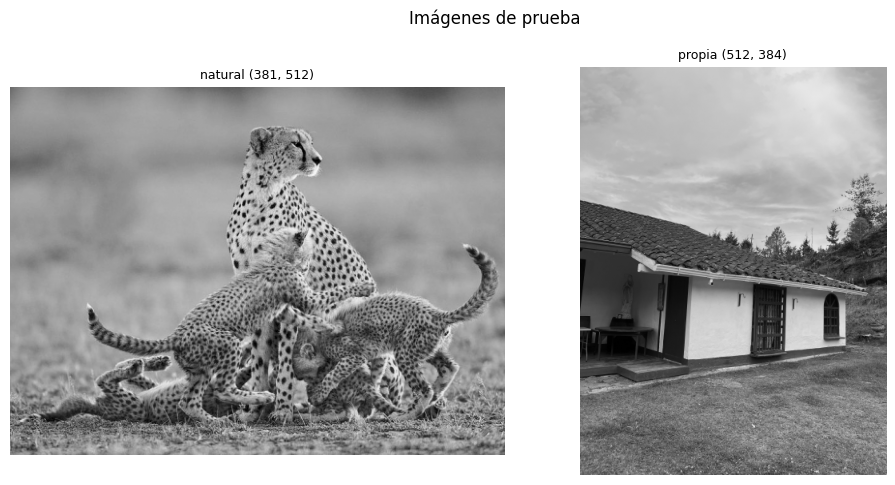

In [3]:
def a_uint8(x):
    # Redondea y satura a [0,255] como uint8
    return np.clip(np.rint(x), 0, 255).astype(np.uint8)

def vis_abs(x, pct=99.5):
    # Visualiza |x| escalando con el percentil `pct` (evita que un pico oscurezca todo)
    x = np.abs(np.asarray(x, np.float64)); m = np.percentile(x, pct)
    return a_uint8(255*np.clip(x/(m+1e-12), 0, 1))

def vis_signed(x, pct=99.5):
    # Visualiza una señal con signo: 0 -> gris medio (128), positivo claro, negativo oscuro
    x = np.asarray(x, np.float64); m = np.percentile(np.abs(x), pct)
    return a_uint8(128 + 127*np.clip(x/(m+1e-12), -1, 1))

def mostrar(imgs, titulos, ncols=4, lado=3.2, suptitle=None):
    # Rejilla de imágenes (gris 0-255 o RGB) con títulos
    n = len(imgs); nrows = int(np.ceil(n/ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(lado*ncols, lado*nrows*0.98), squeeze=False)
    for ax in axs.ravel(): ax.axis('off')
    for ax, im, t in zip(axs.ravel(), imgs, titulos):
        if im.ndim == 2: ax.imshow(im, cmap='gray', vmin=0, vmax=255)
        else:            ax.imshow(im)
        ax.set_title(t, fontsize=9)
    if suptitle: fig.suptitle(suptitle, fontsize=12)
    plt.tight_layout(); plt.show()

def mostrar_par(orig, filt, nombre_filtro, parametros):
    # Original y filtrada LADO A LADO, indicando parámetros
    mostrar([orig, filt], ['Original', f'{nombre_filtro}\n{parametros}'], ncols=2, lado=4.6)

def ksize_sigma(s):
    # Tamaño de kernel Gaussiano = 6σ+1, forzado a impar
    k = int(6*s + 1)
    return k if k % 2 == 1 else k + 1

def tiempo(fn, repeticiones=3):
    # Devuelve (mejor tiempo en s, resultado)
    mejor, r = np.inf, None
    for _ in range(repeticiones):
        t0 = time.perf_counter(); r = fn(); mejor = min(mejor, time.perf_counter()-t0)
    return mejor, r

def metricas(ref, img):
    # PSNR (dB) y SSIM frente a la imagen de referencia limpia
    return psnr(ref, img, data_range=255), ssim(ref, img, data_range=255)

# Vista previa de las imágenes cargadas
mostrar(list(IMAGENES.values()), [f'{k} {v.shape}' for k, v in IMAGENES.items()], ncols=2, lado=5, suptitle='Imágenes de prueba')

---
# 2.1 Catálogo de filtros a probar (alcance de este notebook)

Tabla de los filtros del catálogo que corresponden a los Módulos A y B, con la función usada y los parámetros que se **varían sistemáticamente**. Entre paréntesis, la celda donde se hace cada barrido.

| Filtro | Tipo | Función | Parámetros variados | Dónde |
|---|---|---|---|---|
| Media / Box normalizado | Lineal | `cv2.blur`, `cv2.boxFilter` | k = 3, 5, 9, 15; `normalize=True/False` | A.3b, Pregunta 1.2 |
| Promedio ponderado | Lineal | `cv2.filter2D` | kernel `[1 2 1; 2 4 2; 1 2 1]/16` | A.3b |
| Gaussiano | Lineal | `cv2.GaussianBlur` | σ = 0.5, 1, 2, 4; tamaño 6σ+1 | A.3b, A.4 |
| Mediana | Orden | `cv2.medianBlur` | k = 3, 5, 7 | A.3b, Pregunta 1.1 |
| Mínimo / Máximo | Orden | `cv2.erode` / `cv2.dilate` | 3×3 | A.3 |
| Bilateral | Preserva bordes | `cv2.bilateralFilter` | d, sigmaColor, sigmaSpace | A.3b, Pregunta 1.3 |
| Non-Local Means | Preserva bordes | `cv2.fastNlMeansDenoising` | h = 5, 10, 20 | A.3, A.3b |
| Roberts, Prewitt | Gradiente | `cv2.filter2D` (kernels propios) | dirección x, y, magnitud | B.1 |
| Sobel, Scharr | Gradiente | `cv2.Sobel`, `cv2.Scharr` | ksize = 3, 5, 7; dx, dy | B.1 |
| Laplaciano 4 y 8 vecinos | 2ª derivada | `cv2.Laplacian`, `cv2.filter2D` | kernel 4-vecinos vs 8-vecinos | B.2 |
| LoG y DoG | 2ª derivada | `GaussianBlur` + Laplaciano; resta de Gaussianas | σ₁, σ₂ (razón 1.6) | B.2 |
| Canny | Detector | `cv2.Canny` (+ implementación propia paso a paso) | umbral bajo/alto, σ de suavizado previo | B.3 |
| Unsharp masking / High-boost | Realce | `cv2.addWeighted` | k = 0.5, 1, 2 | B.4 |
| *(extra)* Homomórfico | Frecuencial | log → FFT → H(u,v) → exp | γ_L, γ_H, D₀ | Extra 1 |
| *(extra)* Máscaras de Laws | Textura | `cv2.filter2D` | L5, E5, S5, R5 combinados | Extra 2 |

> Los filtros opcionales *(extra)* —**homomórfico** y **máscaras de energía de Laws**— se desarrollan en la sección «Filtros extra» (después del Módulo B) y aparecen en la galería final.

---
# 2.2 MÓDULO A · Convolución y filtros de suavizado

La convolución 2D es la operación central del filtrado espacial:

$$g(x,y)=\sum_s\sum_t h(s,t)\,f(x-s,\,y-t)$$

Cada píxel de salida es una suma ponderada de sus vecinos con pesos dados por el kernel $h$. Los filtros **paso bajo** atenúan variaciones rápidas (ruido y detalle fino).

---
## A.1 Convolución manual
Se implementan **tres** versiones y se comparan contra `cv2.filter2D`:

1. `conv2d_pixel`: ciclos sobre cada píxel (la definición literal, lentísima).
2. `conv2d_ciclos`: **dos ciclos `for` sobre los índices del kernel** $(s,t)$, vectorizando sobre toda la imagen (lo que pide el enunciado).
3. `conv2d_stride`: vistas de ventanas deslizantes con `np.lib.stride_tricks` + `einsum`.

⚠️ **Detalle importante:** matemáticamente la convolución *voltea* el kernel, mientras que `cv2.filter2D` calcula una **correlación** (no lo voltea). Por eso, para comparar con `filter2D` hay que pasarle el kernel volteado `h[::-1, ::-1]`. En kernels simétricos (Gaussiano, media) no hay diferencia, pero con un kernel asimétrico sí; lo comprobamos abajo.

**Tipos de borde** (cómo se "inventan" los píxeles fuera de la imagen): `BORDER_CONSTANT` (ceros), `BORDER_REPLICATE` (repite el último píxel: `aaa|abcd|ddd`) y `BORDER_REFLECT` (espeja: `dcb|abcd|cba`). Se mapean a `np.pad` con los modos `constant`, `edge` y `symmetric`.

In [4]:
BORDES = {   # nombre OpenCV : (constante OpenCV, modo np.pad equivalente)
    'BORDER_CONSTANT' : (cv2.BORDER_CONSTANT,  'constant'),
    'BORDER_REPLICATE': (cv2.BORDER_REPLICATE, 'edge'),
    'BORDER_REFLECT'  : (cv2.BORDER_REFLECT,   'symmetric'),
}

def _pad(f, kh, kw, borde):
    # Rellena la imagen con (kh//2, kw//2) píxeles según el tipo de borde (kernel de tamaño impar)
    modo = BORDES[borde][1]
    extra = {'constant_values': 0} if modo == 'constant' else {}
    return np.pad(f, ((kh//2, kh//2), (kw//2, kw//2)), mode=modo, **extra)

def conv2d_pixel(f, h, borde='BORDER_REFLECT'):
    # Versión 1: definición literal. Para cada píxel (y,x) suma ponderada de su ventana
    kh, kw = h.shape; H, W = f.shape
    fp = _pad(f.astype(np.float64), kh, kw, borde)
    hv = h[::-1, ::-1]                      # la convolución voltea el kernel
    out = np.zeros((H, W))
    for y in range(H):
        for x in range(W):
            out[y, x] = np.sum(fp[y:y+kh, x:x+kw] * hv)
    return out

def conv2d_ciclos(f, h, borde='BORDER_REFLECT'):
    # Versión 2: DOS ciclos for sobre el kernel (s,t); cada iteración suma una copia desplazada de la imagen
    kh, kw = h.shape; H, W = f.shape
    fp = _pad(f.astype(np.float64), kh, kw, borde)
    hv = h[::-1, ::-1]
    out = np.zeros((H, W))
    for i in range(kh):
        for j in range(kw):
            out += hv[i, j] * fp[i:i+H, j:j+W]
    return out

def conv2d_stride(f, h, borde='BORDER_REFLECT'):
    # Versión 3: ventanas deslizantes (vista sin copia) y contracción con einsum
    kh, kw = h.shape
    fp = _pad(f.astype(np.float64), kh, kw, borde)
    ventanas = sliding_window_view(fp, (kh, kw))          # (H, W, kh, kw)
    return np.einsum('ijkl,kl->ij', ventanas, h[::-1, ::-1])

def conv_cv2(f, h, borde='BORDER_REFLECT'):
    # Referencia: cv2.filter2D (correlación) con el kernel volteado == convolución
    return cv2.filter2D(f.astype(np.float64), cv2.CV_64F, h[::-1, ::-1], borderType=BORDES[borde][0])

In [5]:
# ---- (a) Verificación de exactitud: kernel 5x5 ASIMÉTRICO aleatorio ----
rng = np.random.default_rng(RNG_SEED)
h_asim = rng.random((5, 5)); h_asim /= h_asim.sum()
f = IMAGENES['natural'].astype(np.float64)
crop = f[:64, :64]                                           # recorte pequeño para la versión por píxel

filas = []
for borde in BORDES:
    ref = conv_cv2(f, h_asim, borde)
    ref_crop = conv_cv2(crop, h_asim, borde)
    sin_voltear = cv2.filter2D(f, cv2.CV_64F, h_asim, borderType=BORDES[borde][0])   # correlación (sin voltear)
    filas.append({
        'Borde': borde,
        'Error máx. pixel (64x64)'  : np.abs(conv2d_pixel(crop, h_asim, borde) - ref_crop).max(),
        'Error máx. ciclos kernel'  : np.abs(conv2d_ciclos(f, h_asim, borde) - ref).max(),
        'Error máx. stride_tricks'  : np.abs(conv2d_stride(f, h_asim, borde) - ref).max(),
        'Error si NO se voltea h'   : np.abs(conv2d_ciclos(f, h_asim, borde) - sin_voltear).max(),
    })
display(pd.DataFrame(filas).set_index('Borde').style.format('{:.2e}').set_caption(
    'Error máximo absoluto frente a cv2.filter2D (kernel asimétrico 5x5)'))

,Error máx. pixel (64x64),Error máx. ciclos kernel,Error máx. stride_tricks,Error si NO se voltea h
Borde,,,,
BORDER_CONSTANT,8.53e-14,0.00e+00,1.42e-13,1.32e+01
BORDER_REPLICATE,8.53e-14,0.00e+00,1.42e-13,1.32e+01
BORDER_REFLECT,8.53e-14,0.00e+00,1.42e-13,1.32e+01


**Observación.** Las tres implementaciones coinciden con `cv2.filter2D` hasta el error de redondeo de punto flotante ($\sim10^{-12}$ o menor), **para los tres tipos de borde**. La última columna muestra que, con un kernel asimétrico, olvidar voltear el kernel produce un error grande: confirma que `filter2D` es una correlación y que la convolución exige el volteo.

In [6]:
# ---- (b) Tiempos de ejecución ----
h5 = np.ones((5, 5)) / 25
t_pix, _  = tiempo(lambda: conv2d_pixel(crop, h5), 2)          # 64x64
t_cic, _  = tiempo(lambda: conv2d_ciclos(f, h5))               # imagen completa
t_str, _  = tiempo(lambda: conv2d_stride(f, h5))
t_cv,  _  = tiempo(lambda: conv_cv2(f, h5), 5)
escala = f.size / crop.size
tabla_t = pd.DataFrame({
    'Tiempo (s)': [t_pix, t_pix*escala, t_cic, t_str, t_cv],
    'Imagen'    : ['64x64 (medido)', f'{f.shape[1]}x{f.shape[0]} (EXTRAPOLADO)', 'completa', 'completa', 'completa'],
}, index=['Ciclos por píxel', 'Ciclos por píxel (extrapolado)', 'Dos ciclos sobre el kernel', 'stride_tricks + einsum', 'cv2.filter2D'])
display(tabla_t.style.format({'Tiempo (s)': '{:.5f}'}))
print(f'cv2.filter2D es ~{t_cic/t_cv:,.0f}x más rápido que los dos ciclos sobre el kernel y ~{t_pix*escala/t_cv:,.0f}x más rápido que la versión por píxel (extrapolada).')

,Tiempo (s),Imagen
Ciclos por píxel,0.04840,64x64 (medido)
Ciclos por píxel (extrapolado),2.30486,512x381 (EXTRAPOLADO)
Dos ciclos sobre el kernel,0.01892,completa
stride_tricks + einsum,0.01881,completa
cv2.filter2D,0.00284,completa


cv2.filter2D es ~7x más rápido que los dos ciclos sobre el kernel y ~811x más rápido que la versión por píxel (extrapolada).


**Observación.** La versión por píxel es de lejos la más lenta y su costo crece con el tamaño de la imagen (cientos o miles de veces más lenta que `cv2.filter2D` al extrapolar a la imagen completa). Mover los ciclos de los píxeles ($H\cdot W$ iteraciones) a los coeficientes del kernel ($k^2$ iteraciones) y delegar la suma a NumPy acelera muchísimo, pero `cv2.filter2D` (C/C++ optimizado, SIMD) sigue siendo la mejor opción. *(Los tiempos exactos dependen de la máquina de Colab.)*

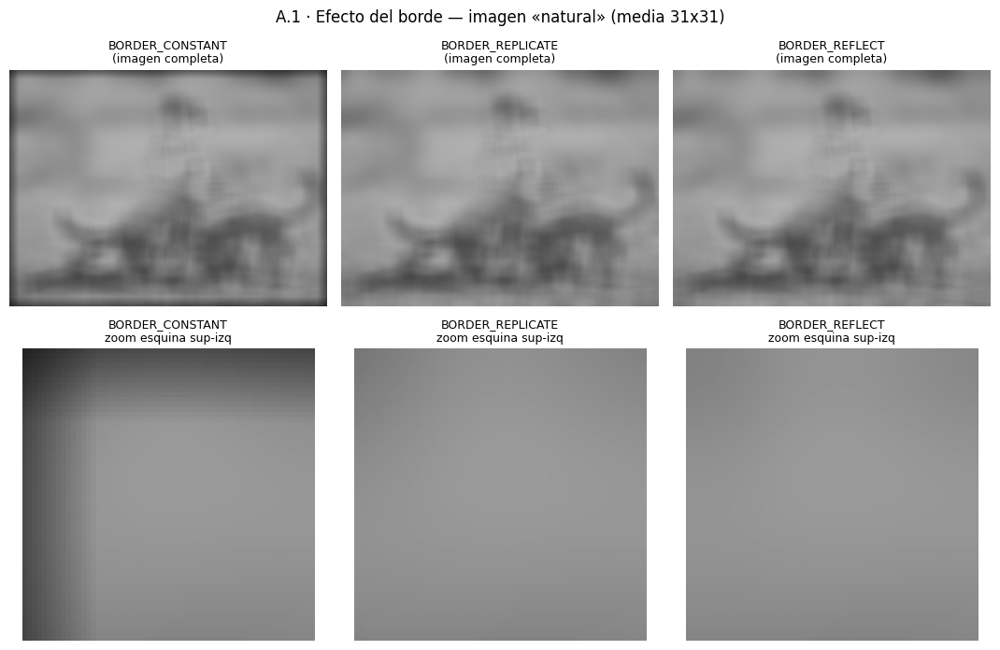

«natural» | brillo medio de la franja de 15 px del borde — original: 139.1 | CONSTANT: 102.5 | REPLICATE: 138.3 | REFLECT: 139.0


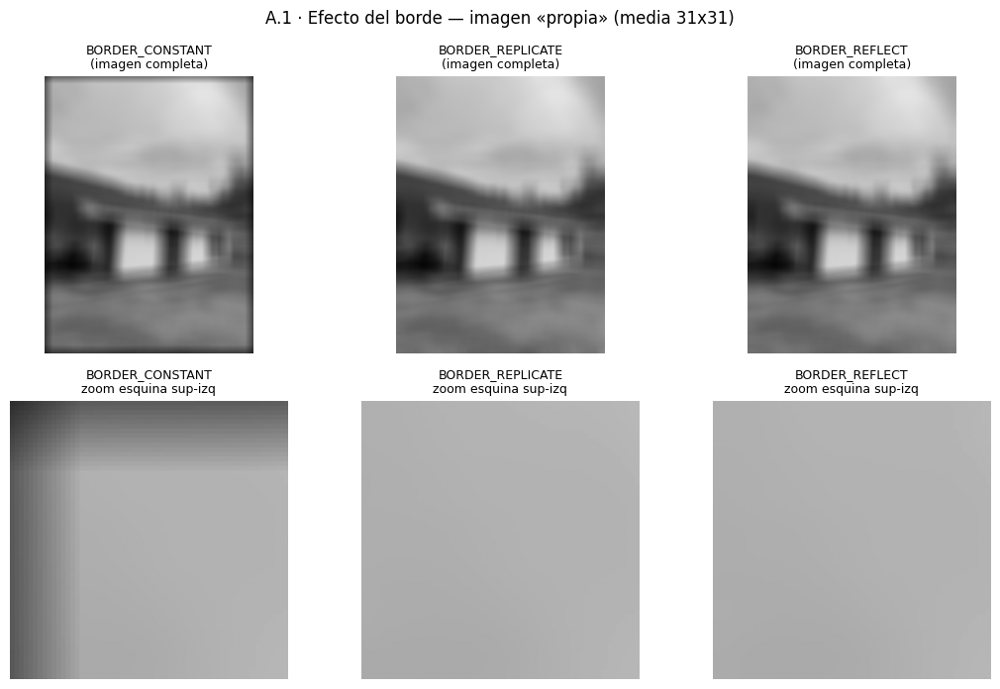

«propia» | brillo medio de la franja de 15 px del borde — original: 132.3 | CONSTANT: 97.5 | REPLICATE: 132.1 | REFLECT: 132.5


In [7]:
# ---- (c) Efecto de los tipos de borde: media 31x31 (kernel grande para que el efecto sea evidente) ----
h31 = np.ones((31, 31)) / 31**2
for nombre, img in IMAGENES.items():
    f_ = img.astype(np.float64)
    outs = {b: conv_cv2(f_, h31, b) for b in BORDES}
    ims, tits = [], []
    for b, o in outs.items():
        ims.append(a_uint8(o));          tits.append(f'{b}\n(imagen completa)')
    for b, o in outs.items():
        ims.append(cv2.resize(a_uint8(o)[:60, :60], None, fx=4, fy=4, interpolation=cv2.INTER_NEAREST))
        tits.append(f'{b}\nzoom esquina sup-izq')
    mostrar(ims, tits, ncols=3, lado=3.6, suptitle=f'A.1 · Efecto del borde — imagen «{nombre}» (media 31x31)')
    banda = np.zeros(f_.shape, bool); banda[:15] = banda[-15:] = True; banda[:, :15] = banda[:, -15:] = True
    ref_i = ~(np.pad(np.ones((f_.shape[0]-30, f_.shape[1]-30), bool), 15))
    print(f'«{nombre}» | brillo medio de la franja de 15 px del borde — original: {f_[banda].mean():.1f} | ' +
          ' | '.join(f'{b.replace("BORDER_","")}: {o[banda].mean():.1f}' for b, o in outs.items()))

**Observación.**
* `BORDER_CONSTANT` supone que fuera de la imagen todo es **negro (0)**: los píxeles cercanos al borde se promedian con ceros y aparece un **marco oscuro** (el brillo medio de la franja del borde cae notablemente respecto al original).
* `BORDER_REPLICATE` y `BORDER_REFLECT` extienden la imagen con valores *plausibles* (copia del borde o espejo) y casi no introducen artefactos; el espejo suele ser el más natural porque conserva la estructura local.
* Regla práctica: usar `REFLECT`/`REFLECT_101` (valor por defecto de OpenCV) salvo que haya una razón para rellenar con ceros.

---
## A.2 Modelos de ruido
Se contamina cada imagen con:

* **Gaussiano aditivo** $g=f+n,\; n\sim\mathcal N(0,\sigma^2)$ con σ = 10 y 25.
* **Sal y pimienta** (impulsivo): una fracción 5 % y 15 % de píxeles se fuerza a 0 o 255 (mitad y mitad).
* **Speckle** (multiplicativo): $g=f+f\cdot n,\; n\sim\mathcal N(0,0.25^2)$; la perturbación es mayor donde la imagen es más brillante.

Se muestran las imágenes ruidosas y su **histograma** (escala log en el eje Y para que se vean los picos de 0 y 255).

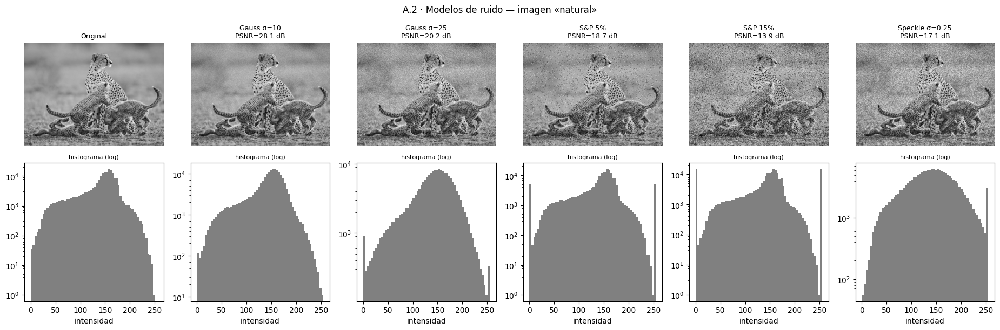

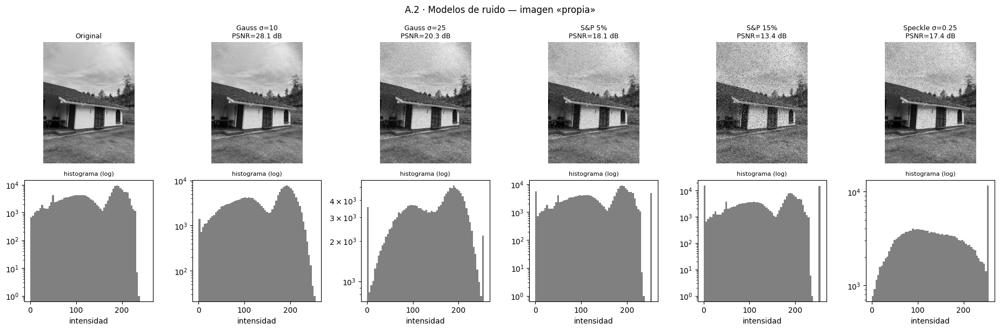

In [8]:
def ruido_gauss(img, sigma, rng):
    return a_uint8(img.astype(np.float64) + rng.normal(0, sigma, img.shape))

def ruido_sal_pimienta(img, prob, rng):
    out = img.copy(); r = rng.random(img.shape)
    out[r < prob/2] = 0                       # pimienta
    out[(r >= prob/2) & (r < prob)] = 255     # sal
    return out

def ruido_speckle(img, sigma, rng):
    f_ = img.astype(np.float64)
    return a_uint8(f_ + f_ * rng.normal(0, sigma, img.shape))

RUIDOS = {
    'Gauss σ=10'    : lambda im, rng: ruido_gauss(im, 10, rng),
    'Gauss σ=25'    : lambda im, rng: ruido_gauss(im, 25, rng),
    'S&P 5%'        : lambda im, rng: ruido_sal_pimienta(im, 0.05, rng),
    'S&P 15%'       : lambda im, rng: ruido_sal_pimienta(im, 0.15, rng),
    'Speckle σ=0.25': lambda im, rng: ruido_speckle(im, 0.25, rng),
}
RUIDOSAS = {}
for nombre, img in IMAGENES.items():
    rng = np.random.default_rng(RNG_SEED)
    RUIDOSAS[nombre] = {k: fn(img, rng) for k, fn in RUIDOS.items()}

for nombre, img in IMAGENES.items():
    items = [('Original', img)] + list(RUIDOSAS[nombre].items())
    fig, axs = plt.subplots(2, len(items), figsize=(3.1*len(items), 6.2))
    for j, (t, im) in enumerate(items):
        axs[0, j].imshow(im, cmap='gray', vmin=0, vmax=255); axs[0, j].axis('off')
        axs[0, j].set_title(t + ('' if t == 'Original' else f'\nPSNR={psnr(img, im, data_range=255):.1f} dB'), fontsize=9)
        axs[1, j].hist(im.ravel(), bins=64, range=(0, 255), color='gray'); axs[1, j].set_yscale('log')
        axs[1, j].set_xlabel('intensidad'); axs[1, j].set_title('histograma (log)', fontsize=8)
    fig.suptitle(f'A.2 · Modelos de ruido — imagen «{nombre}»', fontsize=12)
    plt.tight_layout(); plt.show()

**Observación.**
* **Gaussiano:** el histograma se *ensancha y suaviza* (la convolución del histograma original con una campana); a σ = 25 se pierde buena parte del detalle fino.
* **Sal y pimienta:** el histograma conserva su forma pero aparecen **dos picos aislados en 0 y 255** (visibles gracias a la escala log), de altura proporcional a la densidad de ruido. Son *outliers* extremos y por eso el PSNR cae mucho con 15 %.
* **Speckle:** ensancha el histograma de forma desigual: las zonas claras se degradan más que las oscuras (ruido dependiente de la señal).

---
## A.3 «Batalla de filtros»
Se aplican a **cada** imagen ruidosa: media 5×5, Gaussiano (σ = 1.5), mediana 5×5, mínimo 3×3, máximo 3×3, bilateral (d=9, σ_color=75, σ_space=75) y —como comparación adicional— Non-Local Means (h=15). Se mide **PSNR** y **SSIM** (`skimage.metrics`) contra la imagen limpia. La columna *Sin filtrar* es el punto de partida: un filtro sólo sirve si **supera** ese valor.

In [9]:
def filtro_min(x, k=3): return cv2.erode(x,  np.ones((k, k), np.uint8))
def filtro_max(x, k=3): return cv2.dilate(x, np.ones((k, k), np.uint8))

FILTROS_A3 = {
    'Media 5x5'   : lambda x: cv2.blur(x, (5, 5)),
    'Gauss σ=1.5' : lambda x: cv2.GaussianBlur(x, (ksize_sigma(1.5),)*2, 1.5),
    'Mediana 5x5' : lambda x: cv2.medianBlur(x, 5),
    'Mínimo 3x3'  : filtro_min,
    'Máximo 3x3'  : filtro_max,
    'Bilateral'   : lambda x: cv2.bilateralFilter(x, 9, 75, 75),
    'NLM h=15'    : lambda x: cv2.fastNlMeansDenoising(x, None, h=15, templateWindowSize=7, searchWindowSize=21),
}
RES_A3, TABLAS_A3 = {}, {}
for nombre, img in IMAGENES.items():
    fp, fs = {}, {}
    for rl, rim in RUIDOSAS[nombre].items():
        p, s = metricas(img, rim); P, S = {'Sin filtrar': p}, {'Sin filtrar': s}
        for fl, fn in FILTROS_A3.items():
            out = fn(rim); RES_A3[(nombre, rl, fl)] = out
            P[fl], S[fl] = metricas(img, out)
        fp[rl], fs[rl] = P, S
    TABLAS_A3[nombre] = (pd.DataFrame(fp).T, pd.DataFrame(fs).T)

cols = list(FILTROS_A3)
for nombre, (dp, ds) in TABLAS_A3.items():
    print(f'\n================  IMAGEN «{nombre}»  ================')
    display(dp.style.format('{:.2f}').highlight_max(axis=1, subset=cols, color='#b6f2b6').set_caption('PSNR (dB) — verde = ganador por tipo de ruido'))
    display(ds.style.format('{:.3f}').highlight_max(axis=1, subset=cols, color='#b6f2b6').set_caption('SSIM — verde = ganador por tipo de ruido'))
    gan = pd.DataFrame({'Ganador PSNR': dp[cols].idxmax(axis=1), 'Ganador SSIM': ds[cols].idxmax(axis=1)})
    display(gan.style.set_caption('Filtro ganador en cada caso'))


================  IMAGEN «natural»  ================


,Sin filtrar,Media 5x5,Gauss σ=1.5,Mediana 5x5,Mínimo 3x3,Máximo 3x3,Bilateral,NLM h=15
Gauss σ=10,28.10,23.64,24.39,23.73,17.45,18.07,24.79,31.22
Gauss σ=25,20.22,23.32,24.03,23.22,14.22,14.40,24.70,22.85
S&P 5%,18.66,23.04,23.70,23.78,11.17,12.61,23.31,19.75
S&P 15%,13.90,21.83,22.34,23.62,7.74,9.26,19.15,13.90
Speckle σ=0.25,17.11,22.94,23.63,22.69,12.16,12.09,23.58,17.17


,Sin filtrar,Media 5x5,Gauss σ=1.5,Mediana 5x5,Mínimo 3x3,Máximo 3x3,Bilateral,NLM h=15
Gauss σ=10,0.662,0.762,0.799,0.763,0.651,0.644,0.798,0.932
Gauss σ=25,0.392,0.673,0.720,0.637,0.388,0.406,0.740,0.559
S&P 5%,0.405,0.643,0.691,0.799,0.224,0.214,0.622,0.499
S&P 15%,0.198,0.490,0.543,0.795,0.063,0.067,0.312,0.198
Speckle σ=0.25,0.324,0.586,0.640,0.534,0.275,0.335,0.545,0.329


,Ganador PSNR,Ganador SSIM
Gauss σ=10,NLM h=15,NLM h=15
Gauss σ=25,Bilateral,Bilateral
S&P 5%,Mediana 5x5,Mediana 5x5
S&P 15%,Mediana 5x5,Mediana 5x5
Speckle σ=0.25,Gauss σ=1.5,Gauss σ=1.5



================  IMAGEN «propia»  ================


,Sin filtrar,Media 5x5,Gauss σ=1.5,Mediana 5x5,Mínimo 3x3,Máximo 3x3,Bilateral,NLM h=15
Gauss σ=10,28.13,25.53,26.24,26.08,19.10,18.92,26.91,29.23
Gauss σ=25,20.34,25.05,25.71,25.16,15.02,14.88,26.64,23.43
S&P 5%,18.14,24.49,25.08,26.20,11.18,12.07,22.26,18.88
S&P 15%,13.38,22.27,22.67,25.95,7.59,8.49,16.71,13.39
Speckle σ=0.25,17.38,24.44,25.06,24.08,12.18,13.47,24.59,17.57


,Sin filtrar,Media 5x5,Gauss σ=1.5,Mediana 5x5,Mínimo 3x3,Máximo 3x3,Bilateral,NLM h=15
Gauss σ=10,0.659,0.689,0.729,0.694,0.558,0.575,0.721,0.784
Gauss σ=25,0.345,0.610,0.656,0.575,0.303,0.361,0.684,0.531
S&P 5%,0.375,0.563,0.613,0.730,0.195,0.197,0.438,0.419
S&P 15%,0.146,0.416,0.468,0.725,0.060,0.068,0.198,0.147
Speckle σ=0.25,0.337,0.525,0.579,0.468,0.238,0.413,0.478,0.369


,Ganador PSNR,Ganador SSIM
Gauss σ=10,NLM h=15,NLM h=15
Gauss σ=25,Bilateral,Bilateral
S&P 5%,Mediana 5x5,Mediana 5x5
S&P 15%,Mediana 5x5,Mediana 5x5
Speckle σ=0.25,Gauss σ=1.5,Gauss σ=1.5


In [10]:
# Comparación visual para los dos casos más representativos: ruido Gaussiano σ=25 y sal y pimienta 15 %
for nombre, img in IMAGENES.items():
    for rl in ['Gauss σ=25', 'S&P 15%']:
        ims = [img, RUIDOSAS[nombre][rl]]; tits = ['Original', f'Ruidosa: {rl}']
        for fl in FILTROS_A3:
            ims.append(RES_A3[(nombre, rl, fl)])
            p, s = metricas(img, RES_A3[(nombre, rl, fl)]); tits.append(f'{fl}\nPSNR {p:.1f} | SSIM {s:.3f}')
        mostrar(ims, tits, ncols=5, lado=3.1, suptitle=f'A.3 · «{nombre}» — {rl}')

Output hidden; open in https://colab.research.google.com to view.

**Observaciones (contrástalas con las tablas de *tus* imágenes: los valores exactos cambian, el patrón general no).**

*Nota sobre NLM:* su parámetro `h` debe ser del orden de la desviación del ruido. Con h = 15 destaca en σ=10 (ruido moderado), pero con σ=25 queda por debajo del Gaussiano/bilateral; en el barrido A.3b, con h = 20 NLM obtiene el mejor SSIM en ambas imágenes (y el mejor PSNR en la foto más suave; en una imagen muy texturada lo puede superar por poco un Gaussiano σ=1 o el promedio ponderado), mientras que con h = 5 o 10 apenas filtra.

*Ojo con σ=10 en imágenes muy texturadas* (pelaje, follaje): con ruido moderado, media, Gaussiano, mediana y bilateral pueden quedar **por debajo** del PSNR de la imagen sin filtrar, porque borran más textura de la que quitan de ruido; sólo NLM mejora. Con σ=25 sí mejoran todos.

| Ruido | Ganador esperado | Por qué |
|---|---|---|
| **Gaussiano** (σ=10, 25) | **NLM** o **Bilateral**/Gaussiano | El ruido es aditivo, de media cero y distribuido en todos los píxeles: **promediar** lo reduce. NLM promedia parches *parecidos* de toda la imagen y preserva textura; el bilateral y el Gaussiano promedian localmente (el bilateral cuidando bordes). La mediana también funciona pero degrada algo más la textura. |
| **Sal y pimienta** (5 %, 15 %) | **Mediana** (con diferencia) | Los píxeles corruptos son *outliers* extremos; el promedio los reparte (mancha) mientras que la mediana los descarta (ver Pregunta 1.1). El **bilateral** casi no ayuda: un píxel de 0 o 255 difiere tanto de sus vecinos que ellos le dan peso ≈ 0 y se queda igual (ver Pregunta 1.3). |
| **Speckle** (σ=0.25) | Filtros de suavizado (Gaussiano, media, bilateral) | Con este nivel el ruido multiplicativo se parece a un ruido aditivo cuya amplitud crece con el brillo: los filtros que promedian quedan parejos; la mediana es algo peor y NLM con un `h` bajo casi no filtra (el `h` debe ser comparable a la desviación del ruido). |

Los filtros **mínimo** y **máximo** son los peores: no son filtros de ruido. El mínimo oscurece la imagen y *engrosa* las pimientas (elimina la sal pero propaga la pimienta); el máximo hace lo contrario. Sirven en morfología (erosión/dilatación, Tarea 1), no para denoising.

**Sobre las métricas:** PSNR mide el error cuadrático medio píxel a píxel; SSIM mide similitud estructural (luminancia, contraste, estructura) y se parece más a la percepción humana. Normalmente coinciden en el ganador, pero a veces no: un filtro puede maximizar PSNR suavizando mucho y perder estructura (SSIM menor).

### A.3b Barrido sistemático de parámetros (catálogo 2.1)
Para cada filtro del catálogo se varían los parámetros indicados y se mide PSNR/SSIM sobre dos ruidos: **Gauss σ=25** (donde se espera que ganen los filtros de promediado) y **S&P 5 %** (donde gana la mediana). Se evidencia el compromiso **ruido residual ↔ pérdida de detalle**: un kernel mayor elimina más ruido pero emborrona más.

*(El caso `normalize=False` del filtro de caja satura la imagen y se trata aparte en la Pregunta 1.2.)*

In [11]:
K_POND = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], np.float32) / 16     # promedio ponderado

BARRIDO = []     # (familia, etiqueta, función)
for k in (3, 5, 9, 15):
    BARRIDO.append(('Media (box)', f'k={k}', lambda x, k=k: cv2.blur(x, (k, k))))
BARRIDO.append(('Promedio ponderado', '[1 2 1;2 4 2;1 2 1]/16', lambda x: cv2.filter2D(x, -1, K_POND)))
for s in (0.5, 1, 2, 4):
    BARRIDO.append(('Gaussiano', f'σ={s} (ksize={ksize_sigma(s)})', lambda x, s=s: cv2.GaussianBlur(x, (ksize_sigma(s),)*2, s)))
for k in (3, 5, 7):
    BARRIDO.append(('Mediana', f'k={k}', lambda x, k=k: cv2.medianBlur(x, k)))
for d, sc, ss in [(5, 25, 25), (9, 75, 75), (9, 150, 75), (9, 75, 150), (15, 75, 75)]:
    BARRIDO.append(('Bilateral', f'd={d}, σc={sc}, σs={ss}', lambda x, d=d, sc=sc, ss=ss: cv2.bilateralFilter(x, d, sc, ss)))
for h in (5, 10, 20):
    BARRIDO.append(('Non-Local Means', f'h={h}', lambda x, h=h: cv2.fastNlMeansDenoising(x, None, h=h, templateWindowSize=7, searchWindowSize=21)))

RUIDO_FAMILIA = {'Mediana': 'S&P 5%'}        # en la comparación visual la mediana se muestra con S&P
SALIDAS_B = {}
for nombre, img in IMAGENES.items():
    filas = {}
    for fam, et, fn in BARRIDO:
        fila = {}
        for rl in ('Gauss σ=25', 'S&P 5%'):
            out = fn(RUIDOSAS[nombre][rl]); SALIDAS_B[(nombre, fam, et, rl)] = out
            fila[f'PSNR {rl}'], fila[f'SSIM {rl}'] = metricas(img, out)
        filas[(fam, et)] = fila
    df = pd.DataFrame(filas).T
    print(f'\n================  IMAGEN «{nombre}»  ================')
    display(df.style.format('{:.3f}').format({c: '{:.2f}' for c in df.columns if c.startswith('PSNR')})
            .highlight_max(axis=0, color='#b6f2b6').set_caption('Barrido de parámetros — verde = mejor valor de cada columna'))

    fams = list(dict.fromkeys(f for f, _, _ in BARRIDO)); ncol = 5
    fig, axs = plt.subplots(len(fams), ncol, figsize=(3.0*ncol, 3.0*len(fams)))
    for ax in axs.ravel(): ax.axis('off')
    for i, fam in enumerate(fams):
        rl = RUIDO_FAMILIA.get(fam, 'Gauss σ=25')
        ets = [et for f, et, _ in BARRIDO if f == fam]
        for j, et in enumerate(ets):
            o = SALIDAS_B[(nombre, fam, et, rl)]; p, s = metricas(img, o)
            axs[i, j].imshow(o, cmap='gray', vmin=0, vmax=255)
            axs[i, j].set_title(f'{fam} | {et}\n[{rl}] PSNR {p:.1f}, SSIM {s:.3f}', fontsize=7.5)
    fig.suptitle(f'A.3b · Barrido de parámetros — «{nombre}»', fontsize=12); plt.tight_layout(); plt.show()

Output hidden; open in https://colab.research.google.com to view.

**Observaciones generales del barrido.**
* **Media / Gaussiano:** al aumentar $k$ (o σ) el ruido residual baja pero la imagen se emborrona; el SSIM (y el PSNR del Gaussiano) sube hasta un *óptimo* y luego **decrece** porque la pérdida de detalle supera la ganancia en ruido; en la caja el mejor PSNR ya aparece en k=3, porque su óptimo está en tamaños aún menores. Con σ = 0.5 el filtro casi no actúa; con σ = 4 (o k = 15) la imagen queda muy borrosa. El Gaussiano es más suave que la caja del mismo tamaño porque pondera menos a los píxeles lejanos (la caja produce un emborronado "cuadrado" más agresivo).
* **Promedio ponderado** `[1 2 1; 2 4 2; 1 2 1]/16` es una aproximación binomial de un Gaussiano de σ≈0.85: se comporta como un Gaussiano suave.
* **Mediana:** con S&P 5 % k = 3 ya limpia casi todo; k = 3 es el mejor; k = 5 y 7 empeoran PSNR y SSIM porque redondean esquinas y eliminan detalle fino.
* **Bilateral:** **σ_color** controla la tolerancia a diferencias de intensidad (muy grande ⇒ se comporta como un Gaussiano y borra bordes; muy pequeño ⇒ casi no filtra); **σ_space** controla el alcance espacial (mayor ⇒ más suavizado y más lento), pero **está acotado por `d`**: con `d=9` el vecindario nunca supera 9×9 px, por eso en la tabla (9,75,75) y (9,75,150) dan un resultado prácticamente idéntico (difieren apenas en la 5.ª cifra del SSIM). Para que σ_space actúe hay que aumentar también `d` (o usar `d ≤ 0`).
* **NLM:** $h$ es la fuerza del filtrado: $h$ = 5 deja ruido; $h$ = 20 elimina ruido pero produce un aspecto "plastificado" y pierde textura fina. Debe ser comparable a la desviación del ruido: con σ=25, $h$=20 es claramente mejor, mientras que $h$=5 y $h$=10 casi no filtran (su PSNR es ≈ al de la imagen ruidosa).

---
## A.4 Separabilidad del kernel Gaussiano
Un kernel 2D $h(s,t)$ es **separable** si $h = h_1\,h_2^{T}$ (producto externo de dos vectores). Entonces la convolución 2D equivale a **dos convoluciones 1D** (una por filas y otra por columnas). Si el kernel es $K\times K$, el costo por píxel baja de $K^2$ a $2K$ multiplicaciones (para $K=31$: 961 → 62, es decir ~15.5× menos).

Se demuestra numéricamente que (i) el kernel Gaussiano 2D es el producto externo de dos kernels 1D de `cv2.getGaussianKernel`, (ii) tiene **rango 1** (un solo valor singular distinto de cero), y (iii) ambas formas dan el mismo resultado.

Error máx. |producto externo - fórmula 2D directa| : 3.469446951953614e-18
Primeros 4 valores singulares del kernel 2D       : [0.05663354 0.         0.         0.        ]
Rango numérico del kernel (tol 1e-12)             : 1 (rango 1 ⇒ separable)

Error máx. 2D vs 2x1D (cv2)      : 1.99e-13
Error máx. 2D vs 2x1D (manual)   : 7.96e-13


,Kernel 2D 31x31 (s),Dos pasadas 1D (s),Aceleración (x)
cv2.filter2D,0.01349,0.00853,1.6
Manual (ciclos sobre el kernel),0.55703,0.02648,21.0


Operaciones por píxel: 2D = 961 | 2x1D = 62 | razón teórica = 15.5x


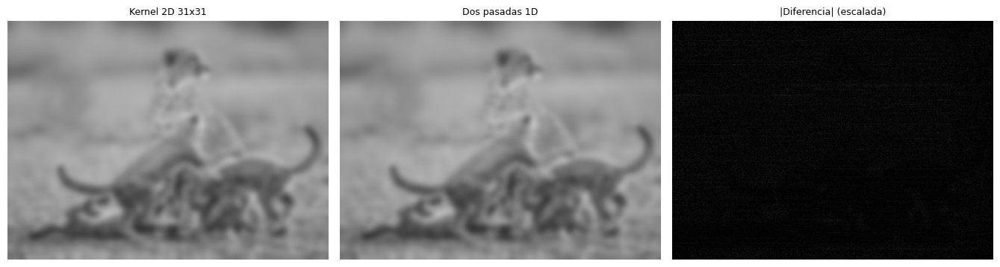

In [12]:
K, SIG = 31, 5.0
g1 = cv2.getGaussianKernel(K, SIG)            # vector columna (K,1), normalizado
g2d_outer = g1 @ g1.T                          # producto externo
# Kernel 2D construido directamente de la fórmula del Gaussiano 2D, normalizado
ax_ = np.arange(K) - K//2
X, Y = np.meshgrid(ax_, ax_)
g2d_formula = np.exp(-(X**2 + Y**2)/(2*SIG**2)); g2d_formula /= g2d_formula.sum()

print('Error máx. |producto externo - fórmula 2D directa| :', np.abs(g2d_outer - g2d_formula).max())
sv = np.linalg.svd(g2d_outer, compute_uv=False)
print('Primeros 4 valores singulares del kernel 2D       :', np.round(sv[:4], 12))
print('Rango numérico del kernel (tol 1e-12)             :', int((sv > 1e-12).sum()), '(rango 1 ⇒ separable)')

# ---- Resultados idénticos y tiempos ----
f = IMAGENES['natural'].astype(np.float64)
t2d_cv, r2d_cv = tiempo(lambda: cv2.filter2D(f, cv2.CV_64F, g2d_outer), 5)
t1d_cv, r1d_cv = tiempo(lambda: cv2.filter2D(cv2.filter2D(f, cv2.CV_64F, g1), cv2.CV_64F, g1.T), 5)
t2d_my, r2d_my = tiempo(lambda: conv2d_ciclos(f, g2d_outer), 2)
t1d_my, r1d_my = tiempo(lambda: conv2d_ciclos(conv2d_ciclos(f, g1), g1.T), 2)    # (31x1) y luego (1x31)

print(f'\nError máx. 2D vs 2x1D (cv2)      : {np.abs(r2d_cv - r1d_cv).max():.2e}')
print(f'Error máx. 2D vs 2x1D (manual)   : {np.abs(r2d_my - r1d_my).max():.2e}')
display(pd.DataFrame({
    'Kernel 2D 31x31 (s)'   : [t2d_cv, t2d_my],
    'Dos pasadas 1D (s)'    : [t1d_cv, t1d_my],
}, index=['cv2.filter2D', 'Manual (ciclos sobre el kernel)']).assign(**{'Aceleración (x)': lambda d: d.iloc[:, 0]/d.iloc[:, 1]})
    .style.format({'Kernel 2D 31x31 (s)': '{:.5f}', 'Dos pasadas 1D (s)': '{:.5f}', 'Aceleración (x)': '{:.1f}'}))
print('Operaciones por píxel: 2D =', K*K, '| 2x1D =', 2*K, f'| razón teórica = {K*K/(2*K):.1f}x')

mostrar([a_uint8(r2d_cv), a_uint8(r1d_cv), vis_abs(r2d_cv - r1d_cv, 100)],
        ['Kernel 2D 31x31', 'Dos pasadas 1D', '|Diferencia| (escalada)'], ncols=3, lado=4.5)

**Observación.** El producto externo de los dos kernels 1D reproduce el kernel 2D con error ~$10^{-17}$ y el kernel tiene **rango 1** (un único valor singular no nulo), lo que *demuestra* la separabilidad. Los resultados 2D y 2×1D son idénticos a precisión de máquina.

En la implementación **manual** la ganancia de tiempo se acerca a la razón teórica de operaciones ($K^2/2K = 15.5\times$). En `cv2.filter2D` la ganancia **depende de la versión de OpenCV y del hardware**: OpenCV ya optimiza internamente los kernels grandes (por ejemplo con FFT), así que dos pasadas 1D pueden resultar igual de rápidas o incluso *más lentas* (en Colab con OpenCV 5.0 se midió ≈0.7×). La ventaja de la separabilidad se ve con claridad en la implementación manual (≈15–18×). En la práctica se usan `cv2.GaussianBlur`/`cv2.sepFilter2D`, que explotan la separabilidad de forma explícita.

---
## Preguntas conceptuales del Módulo A

### Pregunta 1.1 – Mediana vs. Media
Primero un experimento mínimo con una ventana 3×3 que contiene un solo *outlier* (un píxel de sal), y después el cálculo de la probabilidad de que la mediana falle.

Valores ordenados     : [ 97  98  99 100 100 101 102 103 255]
Media   de la ventana : 117.2   (el valor "real" de la zona es ≈ 100 → error de +17.2)
Mediana de la ventana : 100.0   (error de +0.0)
Ventana 3x3, ruido  5% :  P(la mediana falla) = P(más de 4 de 9 corruptos) = 3.32e-05
Ventana 3x3, ruido 15% :  P(la mediana falla) = P(más de 4 de 9 corruptos) = 5.63e-03
Ventana 5x5, ruido  5% :  P(la mediana falla) = P(más de 12 de 25 corruptos) = 3.59e-11
Ventana 5x5, ruido 15% :  P(la mediana falla) = P(más de 12 de 25 corruptos) = 1.69e-05
«natural»: error absoluto medio  media 5x5 = 14.62  |  mediana 5x5 = 8.18
«propia»: error absoluto medio  media 5x5 = 14.88  |  mediana 5x5 = 6.48


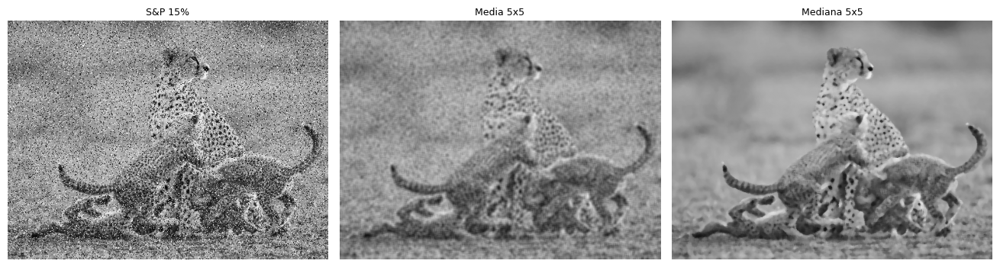

In [13]:
ventana = np.array([[ 98, 101,  99],
                    [100, 255, 102],      # <- píxel de "sal" (outlier)
                    [ 97, 103, 100]])
print('Valores ordenados     :', np.sort(ventana.ravel()))
print(f'Media   de la ventana : {ventana.mean():.1f}   (el valor "real" de la zona es ≈ 100 → error de +{ventana.mean()-100:.1f})')
print(f'Mediana de la ventana : {np.median(ventana):.1f}   (error de {np.median(ventana)-100:+.1f})')

# La mediana falla solo si MÁS DE LA MITAD de la ventana está corrupta.
for k, p in [(3, 0.05), (3, 0.15), (5, 0.05), (5, 0.15)]:
    n = k*k; falla = binom.sf(n//2, n, p)              # P(corruptos > n/2)
    print(f'Ventana {k}x{k}, ruido {int(p*100):2d}% :  P(la mediana falla) = P(más de {n//2} de {n} corruptos) = {falla:.2e}')

# Efecto sobre una imagen real (S&P 15%): error residual de cada filtro
for nombre, img in IMAGENES.items():
    rim = RUIDOSAS[nombre]['S&P 15%']
    e_media = np.abs(cv2.blur(rim, (5, 5)).astype(float) - img).mean()
    e_med   = np.abs(cv2.medianBlur(rim, 5).astype(float) - img).mean()
    print(f'«{nombre}»: error absoluto medio  media 5x5 = {e_media:.2f}  |  mediana 5x5 = {e_med:.2f}')
mostrar([RUIDOSAS['natural']['S&P 15%'], cv2.blur(RUIDOSAS['natural']['S&P 15%'], (5, 5)), cv2.medianBlur(RUIDOSAS['natural']['S&P 15%'], 5)],
        ['S&P 15%', 'Media 5x5', 'Mediana 5x5'], ncols=3, lado=4.4)

**Respuesta 1.1.**

* **La media es un operador lineal:** $\hat f = \frac1N\sum_i f_i$. Cada píxel de la ventana aporta con el mismo peso $1/N$, **incluidos los outliers**. Un píxel de sal (255) en una zona de valor ≈100 desplaza la media en $(255-100)/N$ (≈ +17 para $N=9$): el error no se elimina, **se reparte** sobre los $N$ píxeles de la ventana, dando manchas claras difuminadas. Con 15 % de ruido hay varios outliers por ventana y el sesgo es permanente. En términos de teoría estadística, la media tiene *punto de ruptura* 0: un solo valor arbitrariamente grande puede arruinarla.
* **La mediana es un estadístico de orden:** ordena los $N$ valores y toma el central. Los outliers de sal y pimienta son valores **extremos** (0 o 255) y por tanto terminan en los *extremos* de la lista ordenada, lejos de la posición central. Mientras **menos de la mitad** de la ventana esté corrupta, el valor central es un píxel *genuino* de la vecindad: el outlier se descarta por completo (punto de ruptura 50 %). Además la mediana no inventa valores nuevos ni promedia a través de un borde, por lo que lo preserva mejor que la media.
* **Cuantitativamente** (celda anterior): con ventana 5×5 y 15 % de ruido, la mediana sólo falla si más de 12 de 25 píxeles están corruptos, un evento con probabilidad de apenas ≈ $2\times10^{-5}$ (ver la celda); la media, en cambio, queda sesgada *siempre* que haya un outlier en la ventana. Por eso la mediana elimina "casi por completo" el sal y pimienta y la media sólo lo "difumina".

### Pregunta 1.2 – Normalización del kernel
Se comprueba el efecto con `cv2.boxFilter(normalize=False)` y con kernels cuya suma es distinta de 1.

Brillo medio original                         :   139.96
boxFilter normalize=True  (Σh = 1)            :   139.97
boxFilter normalize=False (Σh = 25) en uint8   :   255.00   ← satura (casi todo = 255)
boxFilter normalize=False (Σh = 25) en float   :  3499.26   ≈ 25 × 139.96 = 3499.08
Porcentaje de píxeles saturados en 255 (uint8): 100.0 %


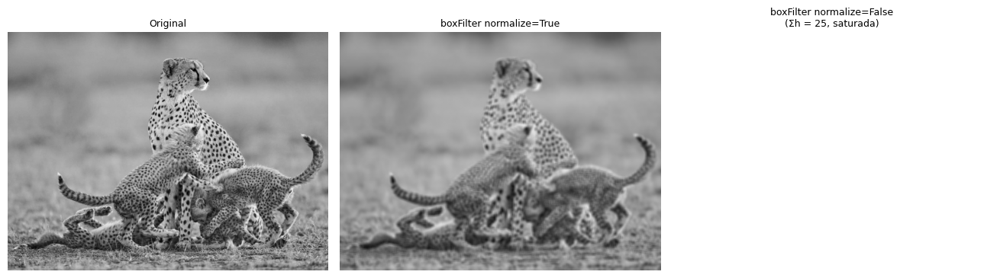

,Brillo teórico Σh·media,Brillo medido (float),"Brillo medido (uint8, satura)"
Σ coeficientes,,,
0.250000,34.99,34.99,34.99
0.500000,69.98,69.98,69.98
0.800000,111.97,111.97,111.97
1.000000,139.96,139.96,139.96
1.200000,167.96,167.96,167.95
2.000000,279.93,279.93,239.03


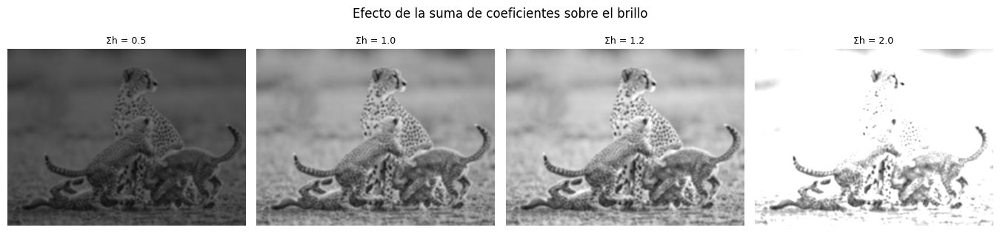

In [14]:
img = IMAGENES['natural']; k = 5
box_norm   = cv2.boxFilter(img, -1, (k, k), normalize=True)
box_nonorm = cv2.boxFilter(img, -1, (k, k), normalize=False)                    # uint8 -> SATURA a 255
box_nonf   = cv2.boxFilter(img.astype(np.float64), cv2.CV_64F, (k, k), normalize=False)   # sin saturar (float)
print(f'Brillo medio original                         : {img.mean():8.2f}')
print(f'boxFilter normalize=True  (Σh = 1)            : {box_norm.mean():8.2f}')
print(f'boxFilter normalize=False (Σh = {k*k}) en uint8   : {box_nonorm.mean():8.2f}   ← satura (casi todo = 255)')
print(f'boxFilter normalize=False (Σh = {k*k}) en float   : {box_nonf.mean():8.2f}   ≈ {k*k} × {img.mean():.2f} = {k*k*img.mean():.2f}')
print(f'Porcentaje de píxeles saturados en 255 (uint8): {100*np.mean(box_nonorm == 255):.1f} %')
mostrar([img, box_norm, box_nonorm], ['Original', 'boxFilter normalize=True', f'boxFilter normalize=False\n(Σh = {k*k}, saturada)'], ncols=3, lado=4.4)

# Barrido de la suma de coeficientes: brillo medio ≈ (Σh) × brillo original
filas = []
f_ = img.astype(np.float64)
for s in [0.25, 0.5, 0.8, 1.0, 1.2, 2.0]:
    kern = np.ones((k, k))/k**2 * s
    sal_f = cv2.filter2D(f_, cv2.CV_64F, kern, borderType=cv2.BORDER_REFLECT)
    sal_u = cv2.filter2D(img, -1, kern, borderType=cv2.BORDER_REFLECT)
    filas.append({'Σ coeficientes': s, 'Brillo teórico Σh·media': s*f_.mean(), 'Brillo medido (float)': sal_f.mean(), 'Brillo medido (uint8, satura)': sal_u.mean()})
display(pd.DataFrame(filas).set_index('Σ coeficientes').style.format('{:.2f}'))
mostrar([cv2.filter2D(img, -1, np.ones((k, k))/k**2*s) for s in (0.5, 1.0, 1.2, 2.0)],
        [f'Σh = {s}' for s in (0.5, 1.0, 1.2, 2.0)], ncols=4, lado=3.4, suptitle='Efecto de la suma de coeficientes sobre el brillo')

**Respuesta 1.2.**
La convolución es lineal, y en una zona de intensidad constante $c$ el resultado es $c\sum h$. De forma general la ganancia a frecuencia cero es $H(0,0)=\sum h(s,t)$, por lo que **el brillo medio de la imagen se multiplica por $\sum h$**:

* $\sum h = 1$ → el brillo medio se conserva (filtro de suavizado "puro").
* $\sum h < 1$ → la imagen se **oscurece** (con 0.5 queda a la mitad).
* $\sum h > 1$ → la imagen se **aclara** y, al ser `uint8`, los valores que superan 255 **saturan**. Con `normalize=False` y $k=5$, $\sum h = 25$: la imagen queda prácticamente blanca (la tabla muestra que, sin saturar, el brillo medio sería ≈ 25 × el original).

Por eso los kernels de suavizado **se normalizan**: un filtro de ruido debe quitar variación, no cambiar la exposición. Al contrario, los kernels de *derivada* (Sobel, Laplaciano, Módulo B) suman **0** a propósito, de modo que respondan sólo a cambios y den ≈ 0 en zonas planas.

### Pregunta 1.3 – Preservación de bordes (filtro bilateral)
Se usa un borde escalón sintético (60 → 180) con ruido Gaussiano σ = 12, para ver con claridad qué hace cada parámetro.

,Desv. estándar en zona plana,Ancho del borde 10–90 % (px)
Configuración,,
Ruidosa (sin filtrar),11.91,0
Gaussiano σ=3,1.15,8
"Bilateral σc=10, σs=3",7.68,0
"Bilateral σc=30, σs=3",2.55,0
"Bilateral σc=100, σs=3",1.77,4
"Bilateral σc=300, σs=3",1.75,4
"Bilateral σc=30, σs=1",4.74,0
"Bilateral σc=30, σs=8",1.78,0


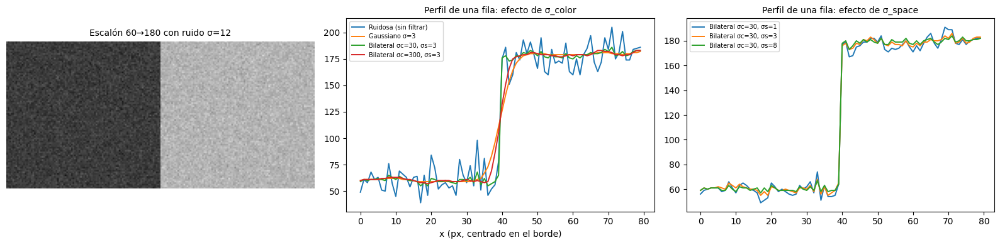

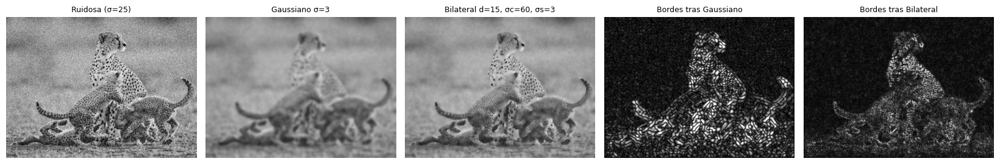

In [15]:
# ---- Escalón sintético con ruido ----
rng = np.random.default_rng(3)
H_, W_ = 96, 200
escalon = np.full((H_, W_), 60.0); escalon[:, W_//2:] = 180.0
esc_ruido = a_uint8(escalon + rng.normal(0, 12, escalon.shape))

def ancho_borde(p, lo=0.1, hi=0.9):
    # Ancho de la transición 10%-90% del perfil medio p (en píxeles)
    a, b = p[10:50].mean(), p[-50:-10].mean(); t = (p - a)/(b - a)
    return int(np.argmax(t > hi) - np.argmax(t > lo))

cfgs = {
    'Ruidosa (sin filtrar)'           : esc_ruido,
    'Gaussiano σ=3'                   : cv2.GaussianBlur(esc_ruido, (ksize_sigma(3),)*2, 3),
    'Bilateral σc=10, σs=3'           : cv2.bilateralFilter(esc_ruido, -1, 10, 3),
    'Bilateral σc=30, σs=3'           : cv2.bilateralFilter(esc_ruido, -1, 30, 3),
    'Bilateral σc=100, σs=3'          : cv2.bilateralFilter(esc_ruido, -1, 100, 3),
    'Bilateral σc=300, σs=3'          : cv2.bilateralFilter(esc_ruido, -1, 300, 3),
    'Bilateral σc=30, σs=1'           : cv2.bilateralFilter(esc_ruido, -1, 30, 1),
    'Bilateral σc=30, σs=8'           : cv2.bilateralFilter(esc_ruido, -1, 30, 8),
}
filas = []
for t, im in cfgs.items():
    filas.append({'Configuración': t, 'Desv. estándar en zona plana': im[:, 10:W_//2-10].std(),
                  'Ancho del borde 10–90 % (px)': ancho_borde(im.astype(float).mean(axis=0))})
display(pd.DataFrame(filas).set_index('Configuración').style.format({'Desv. estándar en zona plana': '{:.2f}'}))

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
axs[0].imshow(esc_ruido, cmap='gray', vmin=0, vmax=255); axs[0].set_title('Escalón 60→180 con ruido σ=12'); axs[0].axis('off')
for t in ['Ruidosa (sin filtrar)', 'Gaussiano σ=3', 'Bilateral σc=30, σs=3', 'Bilateral σc=300, σs=3']:
    axs[1].plot(cfgs[t][H_//2, W_//2-40:W_//2+40], label=t, lw=1.4)
axs[1].set_title('Perfil de una fila: efecto de σ_color'); axs[1].legend(fontsize=7); axs[1].set_xlabel('x (px, centrado en el borde)')
for t in ['Bilateral σc=30, σs=1', 'Bilateral σc=30, σs=3', 'Bilateral σc=30, σs=8']:
    axs[2].plot(cfgs[t][H_//2, W_//2-40:W_//2+40], label=t, lw=1.4)
axs[2].set_title('Perfil de una fila: efecto de σ_space'); axs[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

# ---- Sobre una imagen real: Gaussiano vs bilateral con la misma cantidad de suavizado ----
img = IMAGENES['natural']; rim = RUIDOSAS['natural']['Gauss σ=25']
g = cv2.GaussianBlur(rim, (ksize_sigma(3),)*2, 3); b = cv2.bilateralFilter(rim, 15, 60, 3)
mostrar([rim, g, b, vis_abs(cv2.Sobel(g.astype(float), cv2.CV_64F, 1, 1, ksize=3)), vis_abs(cv2.Sobel(b.astype(float), cv2.CV_64F, 1, 1, ksize=3))],
        ['Ruidosa (σ=25)', 'Gaussiano σ=3', 'Bilateral d=15, σc=60, σs=3', 'Bordes tras Gaussiano', 'Bordes tras Bilateral'], ncols=5, lado=3.3)

**Respuesta 1.3.**
El filtro bilateral es **no lineal**: el peso de cada vecino $q$ para reconstruir el píxel $p$ es el producto de dos Gaussianas,

$$w(p,q)=\underbrace{\exp\!\Big(-\tfrac{\|p-q\|^2}{2\sigma_{space}^2}\Big)}_{\text{cercanía espacial}}\;\cdot\;\underbrace{\exp\!\Big(-\tfrac{(I(p)-I(q))^2}{2\sigma_{color}^2}\Big)}_{\text{similitud de intensidad}},\qquad \hat I(p)=\frac{\sum_q w(p,q)I(q)}{\sum_q w(p,q)}$$

* En una **zona homogénea** las diferencias de intensidad son sólo ruido ($\ll\sigma_{color}$), el segundo factor ≈ 1 y el filtro se comporta como un Gaussiano: promedia y elimina ruido.
* **Cerca de un borde**, los vecinos del *otro lado* tienen $|I(p)-I(q)|$ grande ($\gg\sigma_{color}$): su peso es ≈ 0 y **no contribuyen**. El píxel sólo se promedia con los de su propio lado, así que el borde **no se mezcla** (en la tabla, el ancho 10–90 % del escalón casi no cambia, mientras que el Gaussiano lo ensancha).
* **`sigmaColor`** es la tolerancia en intensidad: si es *pequeño* (≪ ruido) casi nada se promedia y el ruido queda; si es *grande* (≫ contraste del borde) el término de rango deja de discriminar y el filtro degenera en un **Gaussiano que borra los bordes** (ver curva σc = 300). Regla práctica: σ_color de 1 a 3 veces la desviación del ruido y menor que el contraste de los bordes que se quieren preservar.
* **`sigmaSpace`** es el alcance espacial: mayor ⇒ participan píxeles más lejanos (más suavizado y más costo computacional). `d` es el diámetro del vecindario (si `d ≤ 0`, OpenCV lo deriva de `sigmaSpace`).

*Limitación:* ante sal y pimienta el bilateral casi no sirve, porque un píxel de 0 o 255 difiere tanto de todos sus vecinos que ellos tienen peso ≈ 0 y el píxel corrupto se queda consigo mismo (por eso en la Batalla de filtros el bilateral falla en S&P).

---
# 2.3 MÓDULO B · Realce y detección de bordes

Los bordes son cambios bruscos de intensidad: valores altos de la **primera derivada** (gradiente) o **cruces por cero de la segunda derivada** (Laplaciano). Son la base de los descriptores de forma y del HOG de la Parte 2.

$$|\nabla f|=\sqrt{G_x^2+G_y^2},\qquad \theta=\operatorname{atan2}(G_y,G_x),\qquad \nabla^2 f=\frac{\partial^2 f}{\partial x^2}+\frac{\partial^2 f}{\partial y^2}$$

---
## B.1 Operadores de gradiente: Roberts, Prewitt, Sobel y Scharr
Se calculan $G_x$, $G_y$, magnitud y dirección. La dirección se muestra con un **mapa HSV**: *matiz = ángulo* del gradiente, *brillo = magnitud*, saturación al máximo. Se calcula siempre en **`cv2.CV_64F`** (ver explicación más abajo).

Kernels usados (correlación, que es lo que hacen `filter2D`/`Sobel`):

| Operador | $G_x$ | $G_y$ |
|---|---|---|
| Roberts (2×2, diagonales) | `[[1,0],[0,-1]]` | `[[0,1],[-1,0]]` |
| Prewitt | `[[-1,0,1],[-1,0,1],[-1,0,1]]` | transpuesta |
| Sobel | `[[-1,0,1],[-2,0,2],[-1,0,1]]` | transpuesta |
| Scharr | `[[-3,0,3],[-10,0,10],[-3,0,3]]` | transpuesta |

*Nota:* en Roberts los dos kernels miden las derivadas en las **diagonales** (↘ y ↙), por lo que su "ángulo" está rotado 45° respecto al de los demás operadores.

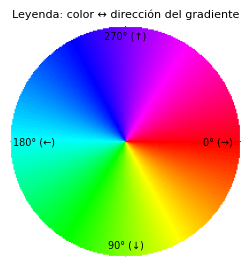

In [16]:
K_ROB_1  = np.array([[1, 0], [0, -1]], np.float64)
K_ROB_2  = np.array([[0, 1], [-1, 0]], np.float64)
K_PREW_X = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float64)
K_PREW_Y = K_PREW_X.T

def gradiente(img, op):
    # Devuelve (Gx, Gy) en float64 para el operador indicado
    f = img.astype(np.float64)
    if op == 'Roberts':
        return cv2.filter2D(f, cv2.CV_64F, K_ROB_1), cv2.filter2D(f, cv2.CV_64F, K_ROB_2)
    if op == 'Prewitt':
        return cv2.filter2D(f, cv2.CV_64F, K_PREW_X), cv2.filter2D(f, cv2.CV_64F, K_PREW_Y)
    if op == 'Sobel':
        return cv2.Sobel(f, cv2.CV_64F, 1, 0, ksize=3), cv2.Sobel(f, cv2.CV_64F, 0, 1, ksize=3)
    if op == 'Scharr':
        return cv2.Scharr(f, cv2.CV_64F, 1, 0), cv2.Scharr(f, cv2.CV_64F, 0, 1)
    raise ValueError(op)

def mapa_hsv(gx, gy):
    # Matiz = ángulo del gradiente (0..2π -> 0..179 en OpenCV), saturación = 255, valor = magnitud (con gamma 0.5 para visualizar)
    mag = np.hypot(gx, gy); ang = np.arctan2(gy, gx) % (2*np.pi)
    h = (ang/(2*np.pi)*179).astype(np.uint8); s = np.full_like(h, 255)
    v = a_uint8(255*np.sqrt(np.clip(mag/(np.percentile(mag, 98)+1e-12), 0, 1)))   # raíz (gamma 0.5) para que se aprecie el color
    return cv2.cvtColor(cv2.merge([h, s, v]), cv2.COLOR_HSV2RGB)

# Leyenda de colores del mapa HSV (el eje y de la imagen apunta hacia abajo)
yy, xx = np.mgrid[-100:101, -100:101]; ang_l = np.arctan2(yy, xx) % (2*np.pi)
rueda = cv2.cvtColor(cv2.merge([(ang_l/(2*np.pi)*179).astype(np.uint8), np.full(ang_l.shape, 255, np.uint8),
                                np.full(ang_l.shape, 255, np.uint8)]), cv2.COLOR_HSV2RGB)
rueda[np.hypot(xx, yy) > 100] = 255
fig, ax = plt.subplots(figsize=(3, 3)); ax.imshow(rueda); ax.axis('off')
ax.set_title('Leyenda: color ↔ dirección del gradiente', fontsize=8)
for txt, (x, y) in {'0° (→)': (180, 100), '90° (↓)': (100, 190), '180° (←)': (20, 100), '270° (↑)': (100, 8)}.items():
    ax.text(x, y, txt, ha='center', va='center', fontsize=7)
plt.show()

In [17]:
OPS = ['Roberts', 'Prewitt', 'Sobel', 'Scharr']
for nombre, img in IMAGENES.items():
    ims, tits = [], []
    for op in OPS:
        gx, gy = gradiente(img, op); mag = np.hypot(gx, gy)
        n1, n2 = ('G1 (↘)', 'G2 (↙)') if op == 'Roberts' else ('Gx', 'Gy')
        ims += [vis_abs(gx), vis_abs(gy), vis_abs(mag), mapa_hsv(gx, gy)]
        tits += [f'{op} |{n1}|', f'{op} |{n2}|', f'{op} magnitud', f'{op} dirección (HSV)']
    mostrar(ims, tits, ncols=4, lado=3.2, suptitle=f'B.1 · Operadores de gradiente — «{nombre}»')
    mostrar_par(img, vis_abs(np.hypot(*gradiente(img, 'Sobel'))), 'Sobel (magnitud)', 'ksize=3, CV_64F')

Output hidden; open in https://colab.research.google.com to view.

**Observaciones.**
* $|G_x|$ resalta los bordes **verticales** (cambios de izquierda a derecha) y $|G_y|$ los **horizontales**; la magnitud los combina. En Roberts, $G_1$ y $G_2$ resaltan bordes diagonales.
* **Roberts** (2×2) localiza muy bien pero es el más **ruidoso**; **Prewitt** y **Sobel** (3×3) promedian a lo largo del borde y son más robustos; **Sobel** da más peso a la fila central ([1 2 1]) → algo más de suavizado y mejor respuesta que Prewitt. **Scharr** optimiza la **isotropía** (la respuesta es más uniforme para bordes en cualquier ángulo) y tiene coeficientes mayores (por eso su magnitud es más alta).
* En el mapa HSV, un mismo objeto con un borde que rodea una región tiene colores *opuestos* en lados opuestos (el gradiente apunta de oscuro a claro). Zonas casi planas quedan negras (magnitud ≈ 0) aunque tengan matiz.

Rango real de Gx (CV_64F)        : [-768, 759]
Rango de Gx con CV_8U            : [0, 255]
Píxeles con derivada NEGATIVA (perdidos al truncar a 0): 46.4 %
Píxeles con derivada > 255 (saturados)                 : 1.9 %


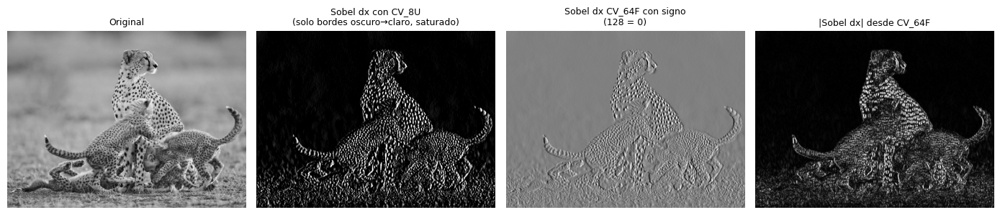

In [18]:
# ---- ¿Por qué NO usar cv2.CV_8U para derivadas? ----
img = IMAGENES['natural']
s_u8  = cv2.Sobel(img, cv2.CV_8U,  1, 0, ksize=3)         # uint8: negativos -> 0, >255 -> 255
s_f64 = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)         # float64: conserva signo y rango completo
print(f'Rango real de Gx (CV_64F)        : [{s_f64.min():.0f}, {s_f64.max():.0f}]')
print(f'Rango de Gx con CV_8U            : [{s_u8.min()}, {s_u8.max()}]')
print(f'Píxeles con derivada NEGATIVA (perdidos al truncar a 0): {100*np.mean(s_f64 < 0):.1f} %')
print(f'Píxeles con derivada > 255 (saturados)                 : {100*np.mean(s_f64 > 255):.1f} %')
mostrar([img, s_u8, vis_signed(s_f64), vis_abs(s_f64)],
        ['Original', 'Sobel dx con CV_8U\n(solo bordes oscuro→claro, saturado)', 'Sobel dx CV_64F con signo\n(128 = 0)', '|Sobel dx| desde CV_64F'], ncols=4, lado=3.5)

**¿Por qué no usar `cv2.CV_8U`?** La derivada es una magnitud **con signo** y de rango mayor que 8 bits (para Sobel 3×3 sobre `uint8`, entre −1020 y +1020):

1. Con `CV_8U` el resultado se **satura**: todos los valores negativos pasan a 0 (se pierden **todos los bordes de transición claro→oscuro**, es decir, aproximadamente la mitad de los bordes) y todos los mayores que 255 se recortan, deformando la magnitud.
2. Se destruye el **signo** que necesita la **dirección** $\theta=\operatorname{atan2}(G_y,G_x)$, y por lo tanto el HOG, la supresión de no-máximos de Canny y el mapa HSV.
3. La magnitud $\sqrt{G_x^2+G_y^2}$ calculada con valores truncados es incorrecta.

La práctica correcta es calcular en `CV_64F` (o `CV_32F`/`CV_16S`), operar y sólo al final tomar valor absoluto/escala para visualizar (`cv2.convertScaleAbs`).

In [19]:
# ---- Variación de ksize (3, 5, 7) y de dirección (dx, dy) ----
# cv2.Scharr sólo existe para 3x3 (equivale a cv2.Sobel con ksize=-1)
for nombre, img in IMAGENES.items():
    f_ = img.astype(np.float64); ims, tits = [], []
    for k in (3, 5, 7):
        gx = cv2.Sobel(f_, cv2.CV_64F, 1, 0, ksize=k); gy = cv2.Sobel(f_, cv2.CV_64F, 0, 1, ksize=k)
        ims += [vis_abs(gx), vis_abs(gy), vis_abs(np.hypot(gx, gy))]
        tits += [f'Sobel k={k}  dx=1,dy=0', f'Sobel k={k}  dx=0,dy=1', f'Sobel k={k}  magnitud']
    gx = cv2.Scharr(f_, cv2.CV_64F, 1, 0); gy = cv2.Scharr(f_, cv2.CV_64F, 0, 1)
    ims += [vis_abs(gx), vis_abs(gy), vis_abs(np.hypot(gx, gy))]
    tits += ['Scharr (3x3)  dx', 'Scharr (3x3)  dy', 'Scharr (3x3)  magnitud']
    mostrar(ims, tits, ncols=3, lado=3.4, suptitle=f'B.1 · Sobel con ksize = 3, 5, 7 y Scharr — «{nombre}»')
print('Máx. |cv2.Scharr - cv2.Sobel(ksize=-1)| =', np.abs(cv2.Scharr(f_, cv2.CV_64F, 1, 0) - cv2.Sobel(f_, cv2.CV_64F, 1, 0, ksize=-1)).max())

Output hidden; open in https://colab.research.google.com to view.

**Observación.** Al aumentar `ksize` el kernel promedia sobre una región mayor perpendicular al borde: los bordes salen **más gruesos y con menos ruido** (se pierden bordes finos y texturas). `ksize=3` localiza mejor pero es más sensible al ruido. `dx=1,dy=0` responde a bordes verticales y `dx=0,dy=1` a horizontales. Scharr (3×3) da una respuesta más isotrópica y fuerte que Sobel 3×3 (de hecho `cv2.Sobel(..., ksize=-1)` es exactamente Scharr).

---
## B.2 Segunda derivada: Laplaciano (4 y 8 vecinos), LoG y DoG
* **Laplaciano 4 vecinos:** `[[0,1,0],[1,-4,1],[0,1,0]]` (en OpenCV equivale a `cv2.Laplacian(ksize=1)`).
* **Laplaciano 8 vecinos:** `[[1,1,1],[1,-8,1],[1,1,1]]` (incluye diagonales; se implementa con `filter2D`).
* **LoG** (Laplaciano del Gaussiano): suavizar con Gaussiano de σ y luego aplicar el Laplaciano. Los bordes están en los **cruces por cero** de la respuesta.
* **DoG** (Diferencia de Gaussianas): $G_{\sigma_1}-G_{\sigma_2}$ con $\sigma_2=1.6\,\sigma_1$, una aproximación al LoG.

Las respuestas tienen signo: se muestran con gris 128 = 0.

In [20]:
K_LAP4 = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float64)
K_LAP8 = np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], np.float64)

def lap(img, k):
    return cv2.filter2D(img.astype(np.float64), cv2.CV_64F, k)

def gauss_f(img, s):
    return cv2.GaussianBlur(img.astype(np.float64), (ksize_sigma(s),)*2, s)

def log_(img, sigma, k=K_LAP4):
    return lap(gauss_f(img, sigma), k)                         # Laplaciano del Gaussiano

def dog(img, s1, razon=1.6):
    return gauss_f(img, s1) - gauss_f(img, razon*s1)            # G(σ1) - G(1.6σ1)

def cruces_por_cero(L, frac=0.05):
    # Marca cruces por cero con respuesta "fuerte": cambio de signo entre vecinos y salto > frac * p99(|L|)
    pos = L > 0; umbral = frac*np.percentile(np.abs(L), 99)
    zc = np.zeros(L.shape, bool)
    zc[:, :-1] |= (pos[:, :-1] != pos[:, 1:]) & (np.abs(L[:, :-1] - L[:, 1:]) > umbral)
    zc[:-1, :] |= (pos[:-1, :] != pos[1:, :]) & (np.abs(L[:-1, :] - L[1:, :]) > umbral)
    return zc

f_ = IMAGENES['natural'].astype(np.float64)
print('Verificación: máx|cv2.Laplacian(ksize=1) - kernel 4-vecinos| =', np.abs(cv2.Laplacian(f_, cv2.CV_64F, ksize=1) - lap(f_, K_LAP4)).max())

Verificación: máx|cv2.Laplacian(ksize=1) - kernel 4-vecinos| = 0.0


In [21]:
for nombre, img in IMAGENES.items():
    for etiqueta, base in [('imagen LIMPIA', img), ('imagen con ruido Gauss σ=10', RUIDOSAS[nombre]['Gauss σ=10'])]:
        L = log_(base, 2)
        ims = [base, vis_signed(lap(base, K_LAP4)), vis_signed(lap(base, K_LAP8)),
               vis_signed(log_(base, 1)), vis_signed(L), vis_signed(log_(base, 3)),
               vis_signed(dog(base, 2)), (cruces_por_cero(L)*255).astype(np.uint8)]
        tits = ['Entrada', 'Laplaciano 4v (directo)', 'Laplaciano 8v (directo)', 'LoG σ=1 (4v)', 'LoG σ=2 (4v)', 'LoG σ=3 (4v)',
                'DoG σ1=2, σ2=3.2', 'Cruces por cero del LoG σ=2']
        mostrar(ims, tits, ncols=4, lado=3.3, suptitle=f'B.2 · «{nombre}» — {etiqueta}')

Output hidden; open in https://colab.research.google.com to view.

**Observaciones.**
* **Laplaciano directo:** responde a cualquier cambio de intensidad, pero en una imagen con ruido la respuesta queda llena de *"sal y pimienta"* (el ruido de alta frecuencia se amplifica; ver Pregunta 1.4). El de **8 vecinos** es todavía más ruidoso y más isotrópico (detecta bien diagonales).
* **LoG:** al suavizar primero, la respuesta se limpia; **σ mayor ⇒ menos ruido pero bordes más "redondeados"** y se pierde detalle fino (σ=1 conserva el detalle, σ=3 sólo el contorno grueso). Los bordes aparecen como un par positivo/negativo cuyo **cruce por cero** los localiza con precisión de sub-píxel, y esos cruces forman **contornos cerrados**.
* **DoG** se ve casi igual que un LoG: es una aproximación.

Correlación entre DoG y -(k-1)σ²·LoG = 0.9445   (cercana a 1 ⇒ el DoG aproxima bien al LoG)
Suma de coeficientes: LoG = -4.51e-17 | DoG = 4.65e-16   (≈ 0: no responden a zonas planas)


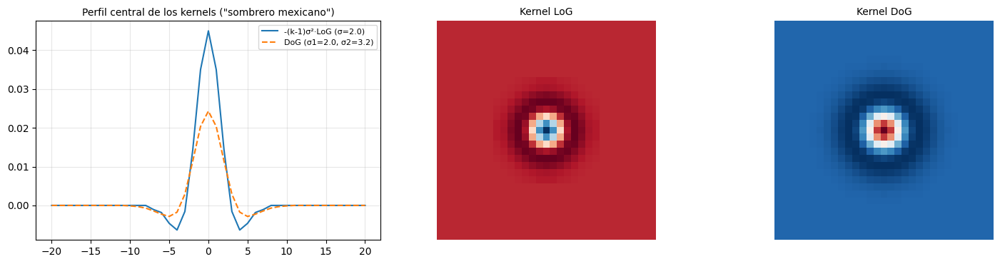

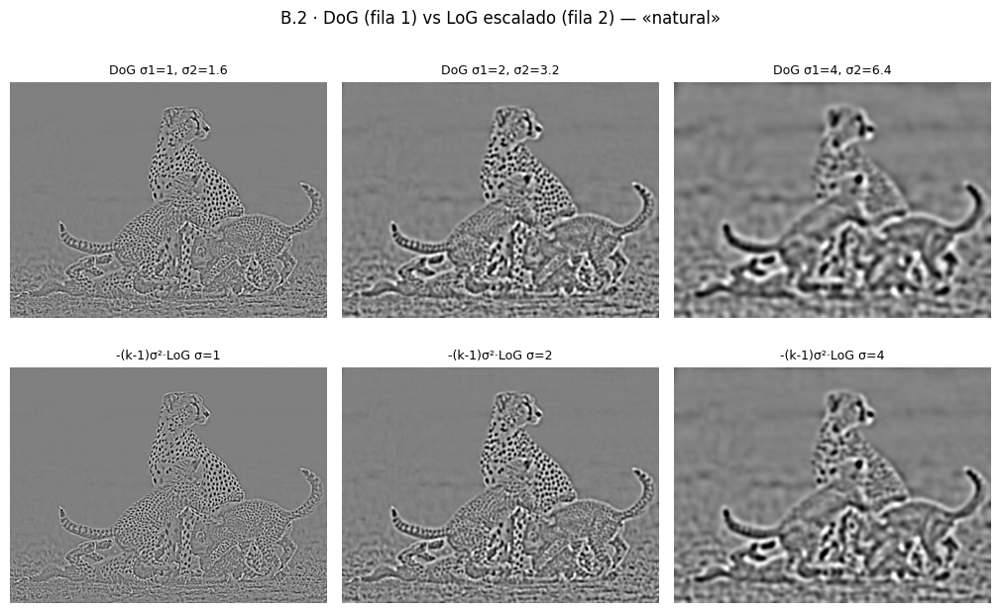

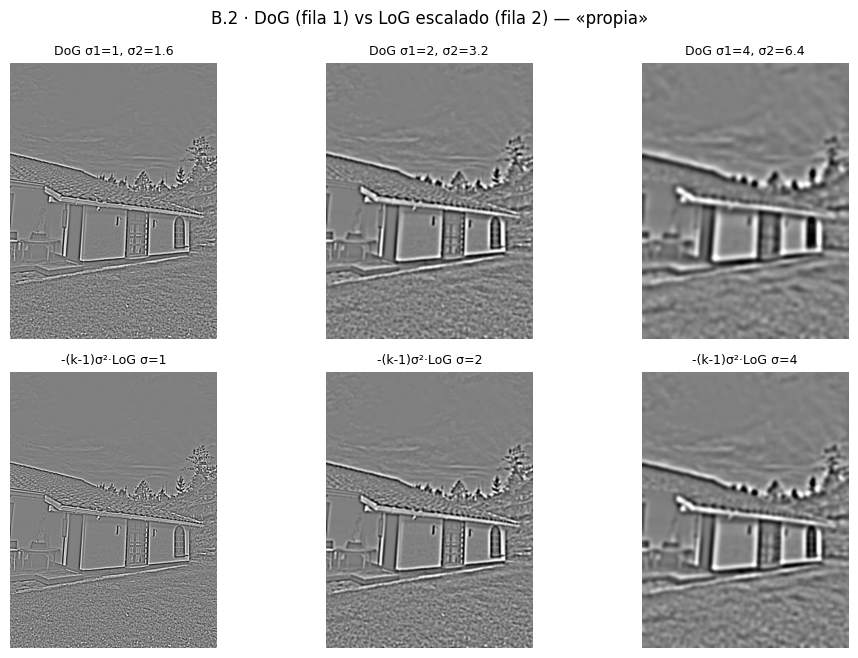

In [22]:
# ---- Comparación cuantitativa LoG vs DoG mediante sus respuestas al impulso (los kernels equivalentes) ----
N = 81; imp = np.zeros((N, N)); imp[N//2, N//2] = 1.0
sigma = 2.0; razon = 1.6
k_log = log_(imp, sigma)                         # kernel LoG equivalente
k_dog = dog(imp, sigma, razon)                   # kernel DoG equivalente
# Teoría: G(kσ) - G(σ) ≈ (k-1)σ²∇²G  =>  DoG(σ, kσ) = G(σ)-G(kσ) ≈ -(k-1)σ² · LoG(σ)
k_log_esc = -(razon - 1)*sigma**2 * k_log
corr = np.corrcoef(k_log_esc.ravel(), k_dog.ravel())[0, 1]
print(f'Correlación entre DoG y -(k-1)σ²·LoG = {corr:.4f}   (cercana a 1 ⇒ el DoG aproxima bien al LoG)')
print(f'Suma de coeficientes: LoG = {k_log.sum():.2e} | DoG = {k_dog.sum():.2e}   (≈ 0: no responden a zonas planas)')

c = N//2; xs = np.arange(-20, 21)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
axs[0].plot(xs, k_log_esc[c, c-20:c+21], label=f'-(k-1)σ²·LoG (σ={sigma})'); axs[0].plot(xs, k_dog[c, c-20:c+21], '--', label=f'DoG (σ1={sigma}, σ2={razon*sigma:.1f})')
axs[0].set_title('Perfil central de los kernels ("sombrero mexicano")'); axs[0].legend(fontsize=8); axs[0].grid(alpha=.3)
for ax, k, t in [(axs[1], k_log, 'Kernel LoG'), (axs[2], k_dog, 'Kernel DoG')]:
    ax.imshow(k[c-15:c+16, c-15:c+16], cmap='RdBu_r'); ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.show()

# DoG para distintos σ1 vs LoG con la misma escala
for nombre, img in IMAGENES.items():
    ims = [vis_signed(dog(img, s)) for s in (1, 2, 4)] + [vis_signed(-(razon-1)*s**2*log_(img, s)) for s in (1, 2, 4)]
    tits = [f'DoG σ1={s}, σ2={razon*s:.1f}' for s in (1, 2, 4)] + [f'-(k-1)σ²·LoG σ={s}' for s in (1, 2, 4)]
    mostrar(ims, tits, ncols=3, lado=3.4, suptitle=f'B.2 · DoG (fila 1) vs LoG escalado (fila 2) — «{nombre}»')

**Observación.** Los kernels de LoG y DoG tienen la misma forma de "sombrero mexicano" y su correlación es muy alta (≈ 0.94 con σ=2 y razón 1.6, valor impreso arriba); ambos suman ≈ 0 (no responden a zonas uniformes). El DoG es más barato (dos suavizados Gaussianos y una resta, aprovechando la separabilidad) y es la base de detectores de puntos de interés como SIFT. La razón 1.6 entre σ's es la que mejor aproxima el LoG.

---
## B.3 Canny paso a paso
El detector de Canny tiene cuatro etapas:

1. **Suavizado Gaussiano** (reduce ruido; `cv2.Canny` **no** suaviza internamente, hay que hacerlo antes).
2. **Gradiente** (Sobel): magnitud y dirección.
3. **Supresión de no-máximos (NMS):** deja sólo el máximo local de la magnitud *a lo largo de la dirección del gradiente* → bordes de 1 píxel.
4. **Umbralización con histéresis:** píxeles $> T_{alto}$ son **fuertes**; los $\in(T_{bajo},T_{alto}]$ son **débiles** y sólo se aceptan si están conectados (8 vecinos) a algún píxel fuerte.

Se implementan las etapas manualmente (NMS e histéresis propias) y se compara contra `cv2.Canny`.

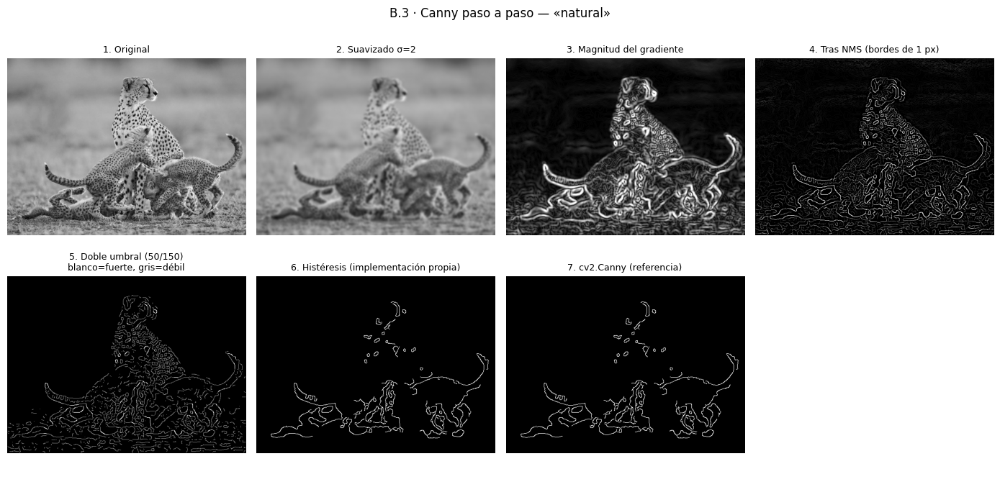

«natural»  propia vs cv2.Canny (tolerancia 1 px): precisión=0.999  recall=1.000  F1=1.000   | píxeles borde propia=4072  cv2=4047


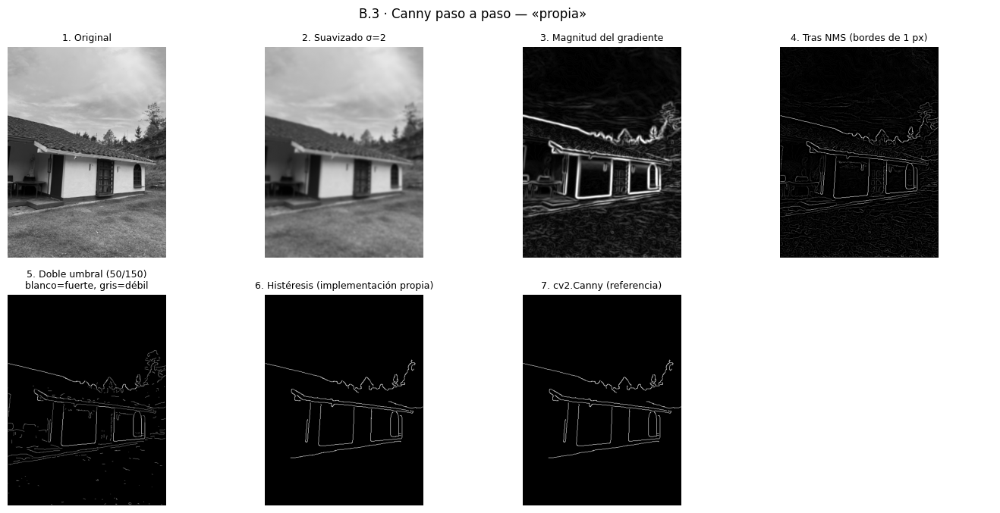

«propia»  propia vs cv2.Canny (tolerancia 1 px): precisión=1.000  recall=1.000  F1=1.000   | píxeles borde propia=2617  cv2=2601


In [23]:
def supresion_no_maximos(mag, ang_deg):
    # NMS: conserva un píxel sólo si su magnitud es >= a la de sus dos vecinos en la dirección del gradiente.
    # Se cuantiza el ángulo en 4 sectores. El eje y apunta hacia abajo, por eso 45° = (↘/↖) y 135° = (↙/↗).
    m = mag
    izq, der = np.roll(m, 1, 1), np.roll(m, -1, 1)
    arr, aba = np.roll(m, 1, 0), np.roll(m, -1, 0)
    ul, dr = np.roll(np.roll(m, 1, 0), 1, 1),  np.roll(np.roll(m, -1, 0), -1, 1)
    ur, dl = np.roll(np.roll(m, 1, 0), -1, 1), np.roll(np.roll(m, -1, 0), 1, 1)
    a = ang_deg % 180
    s0   = (a < 22.5) | (a >= 157.5)
    s45  = (a >= 22.5) & (a < 67.5)
    s90  = (a >= 67.5) & (a < 112.5)
    s135 = (a >= 112.5) & (a < 157.5)
    es_max = np.zeros(m.shape, bool)
    es_max[s0]   = (m >= izq)[s0]  & (m >= der)[s0]
    es_max[s45]  = (m >= ul)[s45]  & (m >= dr)[s45]
    es_max[s90]  = (m >= arr)[s90] & (m >= aba)[s90]
    es_max[s135] = (m >= ur)[s135] & (m >= dl)[s135]
    out = np.where(es_max, m, 0.0)
    out[0, :] = out[-1, :] = 0; out[:, 0] = out[:, -1] = 0       # descarta bordes (np.roll da la vuelta)
    return out

def histeresis(nms, bajo, alto):
    fuerte = nms > alto
    candidato = nms > bajo                                       # fuertes + débiles
    lab, n = ndi.label(candidato, structure=np.ones((3, 3), int))   # componentes conexas con 8 vecinos
    ids = np.unique(lab[fuerte]); ids = ids[ids > 0]
    return np.isin(lab, ids), fuerte, candidato & ~fuerte

def canny_pasos(img, sigma, bajo, alto):
    b = cv2.GaussianBlur(img, (ksize_sigma(sigma),)*2, sigma)
    gx = cv2.Sobel(b, cv2.CV_64F, 1, 0, ksize=3); gy = cv2.Sobel(b, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.hypot(gx, gy); ang = np.rad2deg(np.arctan2(gy, gx))
    nms = supresion_no_maximos(mag, ang)
    final, fuerte, debil = histeresis(nms, bajo, alto)
    return dict(suavizada=b, mag=mag, nms=nms, fuerte=fuerte, debil=debil, final=final)

def comparar_bordes(a, b, tol=1):
    # Precisión/recall/F1 entre mapas de bordes con tolerancia de `tol` píxel
    k = np.ones((2*tol+1,)*2, np.uint8)
    da, db = cv2.dilate(a.astype(np.uint8), k) > 0, cv2.dilate(b.astype(np.uint8), k) > 0
    p = (a & db).sum()/max(a.sum(), 1); r = (b & da).sum()/max(b.sum(), 1)
    return p, r, 2*p*r/max(p + r, 1e-12)

SIG_C, LO_C, HI_C = 2, 50, 150
for nombre, img in IMAGENES.items():
    R = canny_pasos(img, SIG_C, LO_C, HI_C)
    ref = cv2.Canny(R['suavizada'], LO_C, HI_C, L2gradient=True) > 0
    p, r, f1 = comparar_bordes(R['final'], ref)
    doble = np.zeros(img.shape, np.uint8); doble[R['debil']] = 128; doble[R['fuerte']] = 255
    ims = [img, R['suavizada'], vis_abs(R['mag']), vis_abs(R['nms']), doble, (R['final']*255).astype(np.uint8), (ref*255).astype(np.uint8)]
    tits = ['1. Original', f'2. Suavizado σ={SIG_C}', '3. Magnitud del gradiente', '4. Tras NMS (bordes de 1 px)',
            f'5. Doble umbral ({LO_C}/{HI_C})\nblanco=fuerte, gris=débil', '6. Histéresis (implementación propia)', '7. cv2.Canny (referencia)']
    mostrar(ims, tits, ncols=4, lado=3.5, suptitle=f'B.3 · Canny paso a paso — «{nombre}»')
    print(f'«{nombre}»  propia vs cv2.Canny (tolerancia 1 px): precisión={p:.3f}  recall={r:.3f}  F1={f1:.3f}   '
          f'| píxeles borde propia={R["final"].sum()}  cv2={ref.sum()}')

**Observación.** La implementación propia reproduce a `cv2.Canny` con F1 muy alto (las pequeñas diferencias vienen de empates en la NMS y de detalles de implementación de OpenCV). Se aprecia cómo la magnitud forma **bandas anchas** alrededor de los bordes, la NMS las **adelgaza a 1 píxel**, el doble umbral separa candidatos *fuertes* (blanco) y *débiles* (gris), y la histéresis conserva sólo los débiles conectados a fuertes.

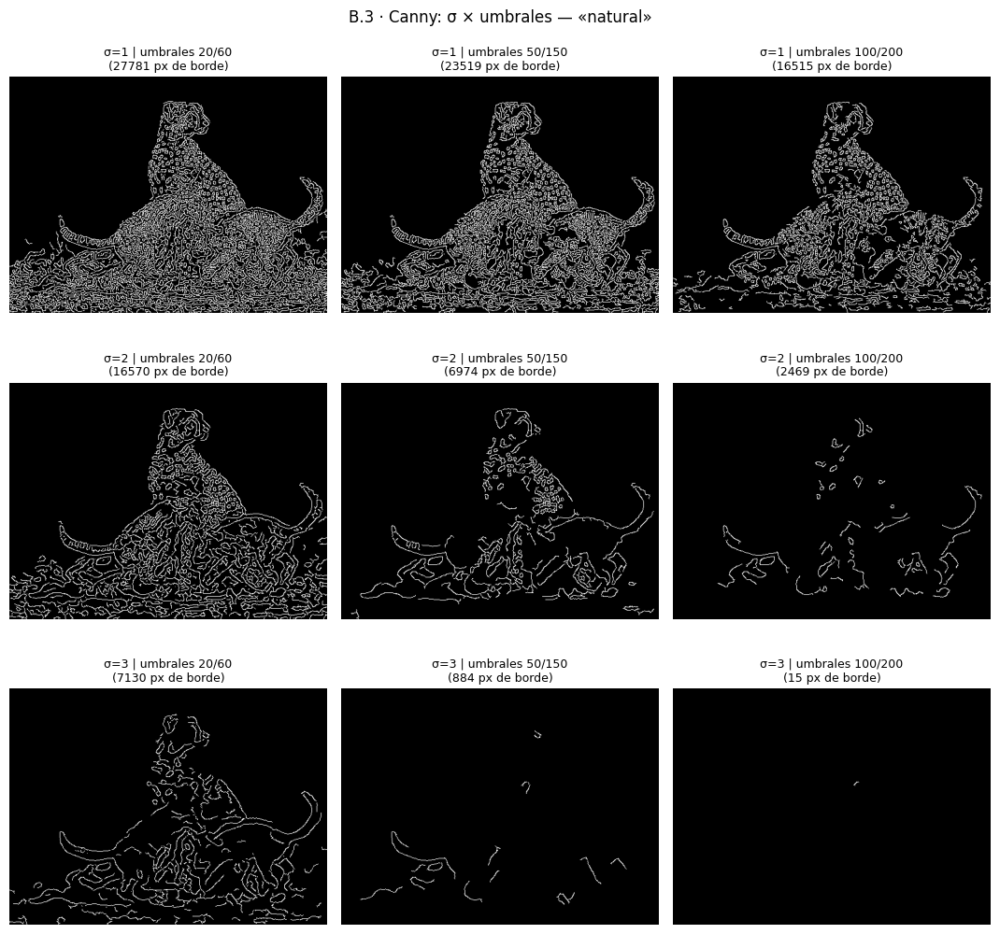

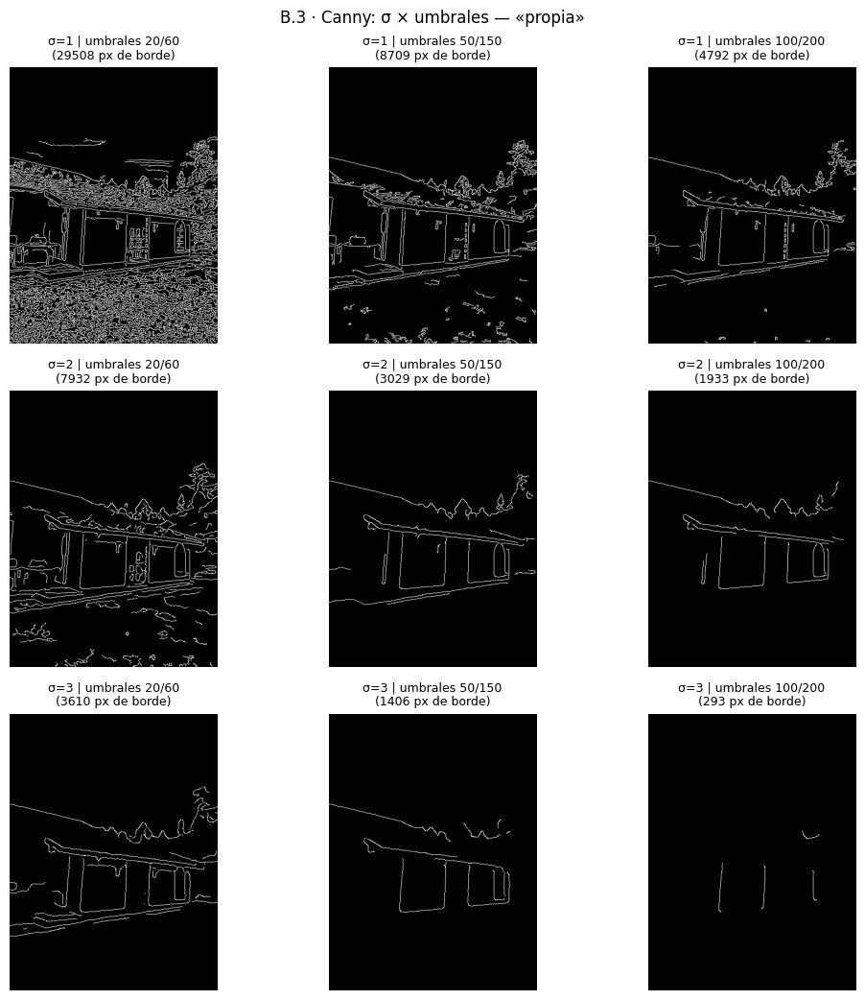

In [24]:
# ---- Matriz visual: σ de suavizado previo (1, 2, 3) × parejas de umbrales (20/60, 50/150, 100/200) ----
UMBRALES = [(20, 60), (50, 150), (100, 200)]
for nombre, img in IMAGENES.items():
    ims, tits = [], []
    for s in (1, 2, 3):
        b = cv2.GaussianBlur(img, (ksize_sigma(s),)*2, s)
        for lo, hi in UMBRALES:
            e = cv2.Canny(b, lo, hi); ims.append(e); tits.append(f'σ={s} | umbrales {lo}/{hi}\n({(e > 0).sum()} px de borde)')
    mostrar(ims, tits, ncols=3, lado=3.6, suptitle=f'B.3 · Canny: σ × umbrales — «{nombre}»')

**Observación.**
* **σ pequeño (1):** muchos bordes, incluyendo ruido y textura fina; **σ grande (3):** sólo contornos principales, bordes algo desplazados y se pierden detalles.
* **Umbrales bajos (20/60):** muchos falsos bordes (ruido, texturas); **altos (100/200):** contornos limpios pero **fragmentados** y se pierden bordes débiles. 50/150 suele ser un buen compromiso en estas imágenes. Hay una interacción: con más suavizado, la magnitud del gradiente baja, así que los mismos umbrales detectan menos.

### Regla automática de umbrales basada en la mediana
Un umbral fijo no sirve para todas las imágenes (una foto oscura o clara tiene magnitudes de gradiente distintas). Una regla común usa la **mediana $v$ de las intensidades** de la imagen suavizada:

$$T_{bajo}=\max\big(0,\,(1-\varsigma)\,v\big),\qquad T_{alto}=\min\big(255,\,(1+\varsigma)\,v\big),\qquad \varsigma\approx0.33$$

Se prueba sobre la imagen normal y sobre una versión **oscura** (corrección gamma 2.0) comparada con la pareja fija 100/200.

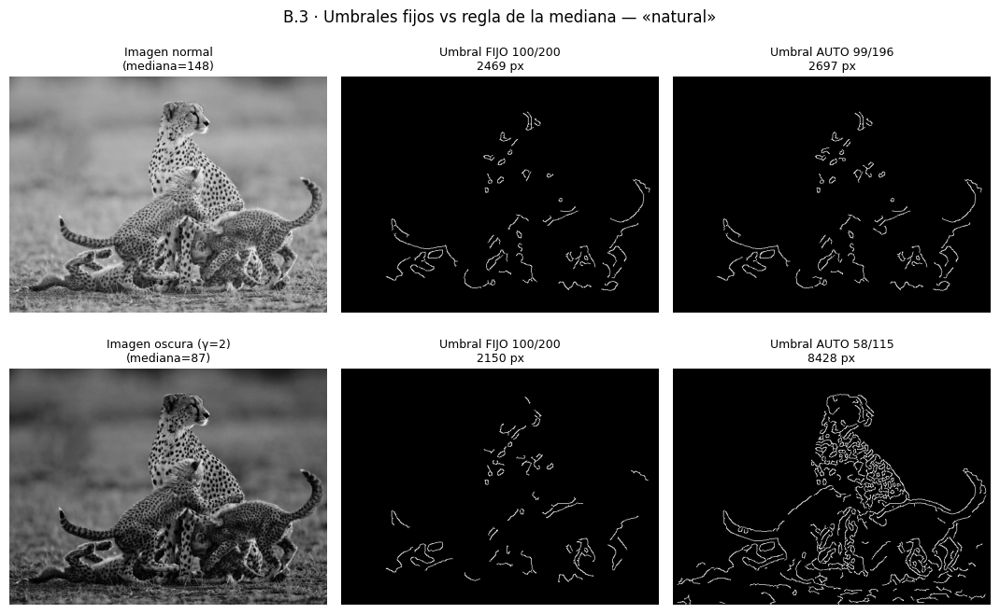

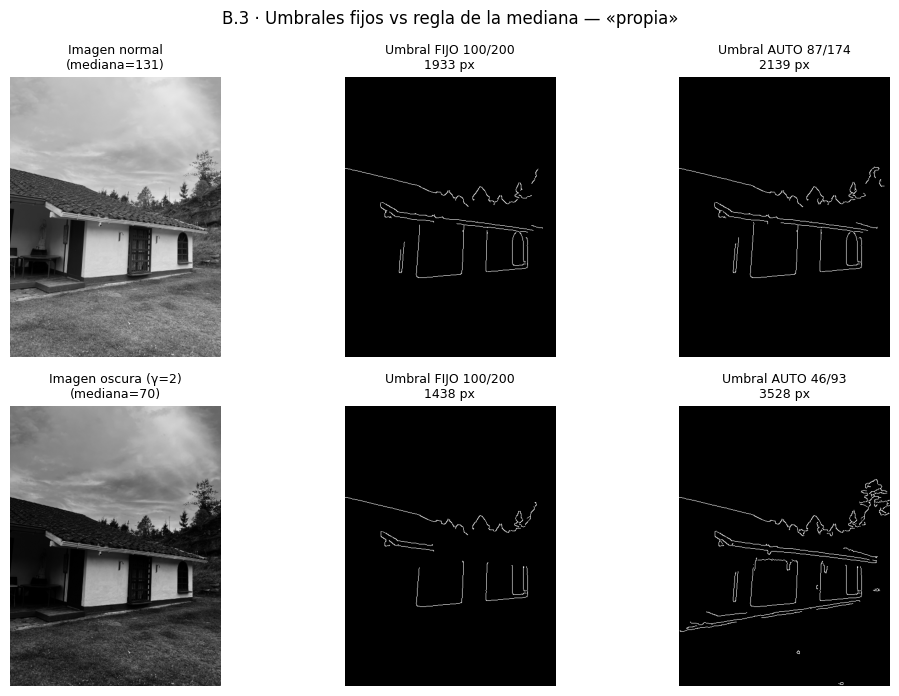

In [25]:
def canny_auto(img, sigma_blur=2, var=0.33):
    b = cv2.GaussianBlur(img, (ksize_sigma(sigma_blur),)*2, sigma_blur)
    v = float(np.median(b)); lo = int(max(0, (1-var)*v)); hi = int(min(255, (1+var)*v))
    return cv2.Canny(b, lo, hi), lo, hi

def oscurecer(img, gamma=2.0):
    return a_uint8(255*(img/255.0)**gamma)

for nombre, img in IMAGENES.items():
    osc = oscurecer(img); ims, tits = [], []
    for etiqueta, im in [('normal', img), ('oscura (γ=2)', osc)]:
        b = cv2.GaussianBlur(im, (ksize_sigma(2),)*2, 2)
        e_fijo = cv2.Canny(b, 100, 200); e_aut, lo, hi = canny_auto(im)
        ims += [im, e_fijo, e_aut]
        tits += [f'Imagen {etiqueta}\n(mediana={np.median(b):.0f})', f'Umbral FIJO 100/200\n{(e_fijo > 0).sum()} px', f'Umbral AUTO {lo}/{hi}\n{(e_aut > 0).sum()} px']
    mostrar(ims, tits, ncols=3, lado=3.6, suptitle=f'B.3 · Umbrales fijos vs regla de la mediana — «{nombre}»')

**Observación.** Con la imagen oscura, los umbrales fijos 100/200 quedan *por encima* de casi todas las magnitudes de gradiente y se detectan muy pocos bordes. La regla de la mediana **se adapta** a la exposición: baja los umbrales cuando la imagen es oscura (y los sube cuando es clara) y mantiene un nivel de detalle comparable. Es una heurística simple y robusta; alternativas son usar Otsu sobre la magnitud del gradiente o percentiles de la magnitud.

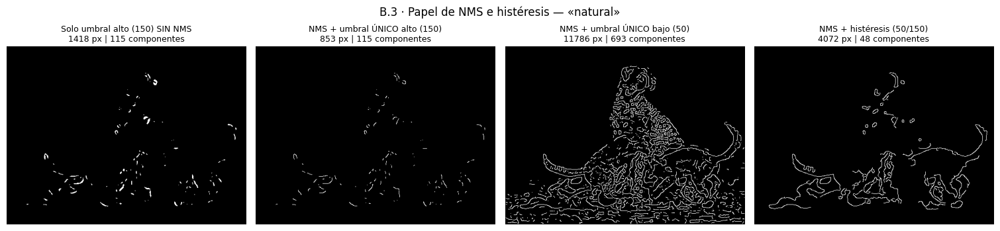

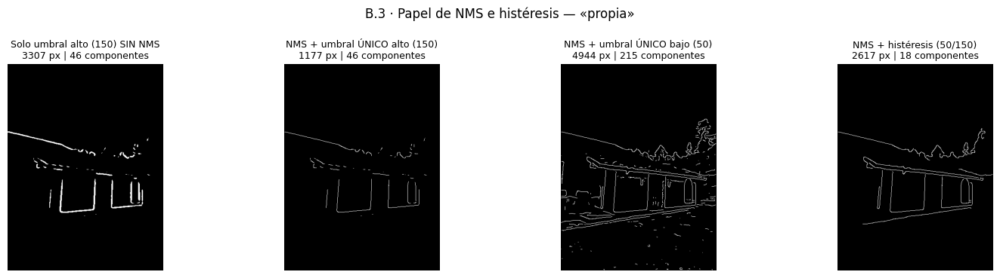

In [26]:
# ---- ¿Para qué sirven NMS e histéresis? Comparación de variantes (insumo para la Pregunta 1.5) ----
def n_componentes(mask):
    return ndi.label(mask, structure=np.ones((3, 3), int))[1]

for nombre, img in IMAGENES.items():
    R = canny_pasos(img, 2, LO_C, HI_C); mag, nms = R['mag'], R['nms']
    variantes = {
        f'Solo umbral alto ({HI_C}) SIN NMS':   mag > HI_C,
        f'NMS + umbral ÚNICO alto ({HI_C})':    nms > HI_C,
        f'NMS + umbral ÚNICO bajo ({LO_C})':    nms > LO_C,
        f'NMS + histéresis ({LO_C}/{HI_C})':    R['final'],
    }
    ims = [(m*255).astype(np.uint8) for m in variantes.values()]
    tits = [f'{t}\n{m.sum()} px | {n_componentes(m)} componentes' for t, m in variantes.items()]
    mostrar(ims, tits, ncols=4, lado=3.8, suptitle=f'B.3 · Papel de NMS e histéresis — «{nombre}»')

**Observación.** (i) *Sin NMS*, los bordes son bandas gruesas (muchos píxeles). (ii) Con NMS y un **umbral único alto**, los contornos delgados se **rompen** (muchos fragmentos: muchas componentes conexas) y se pierden bordes débiles. (iii) Con un **umbral único bajo** aparecen muchos bordes espurios de ruido y textura. (iv) La **histéresis** mantiene los contornos continuos sin añadir el ruido aislado: mantiene casi la misma cantidad de bordes largos que el umbral bajo pero sin la suciedad, y con menos fragmentos que el umbral alto.

---
## B.4 Realce de nitidez: Unsharp masking y High-boost
Se suma al original el **detalle de alta frecuencia** (original menos versión suavizada), amplificado por un factor $k$:

$$g = f + k\,(f - f_{suav}),\qquad f_{suav}=G_\sigma * f$$

* $k=1$: *unsharp masking* clásico. $k>1$: **high-boost** (énfasis extra de alta frecuencia). Equivalente: $g=(1+k)f-k\,f_{suav}$, que es `cv2.addWeighted(f, 1+k, f_suav, -k, 0)`.
* Se evalúa $k=0.5,\,1,\,2$ con σ = 2.

Máx |unsharp propio - cv2.addWeighted| (k=1) = 1 (diferencia por redondeo en uint8)


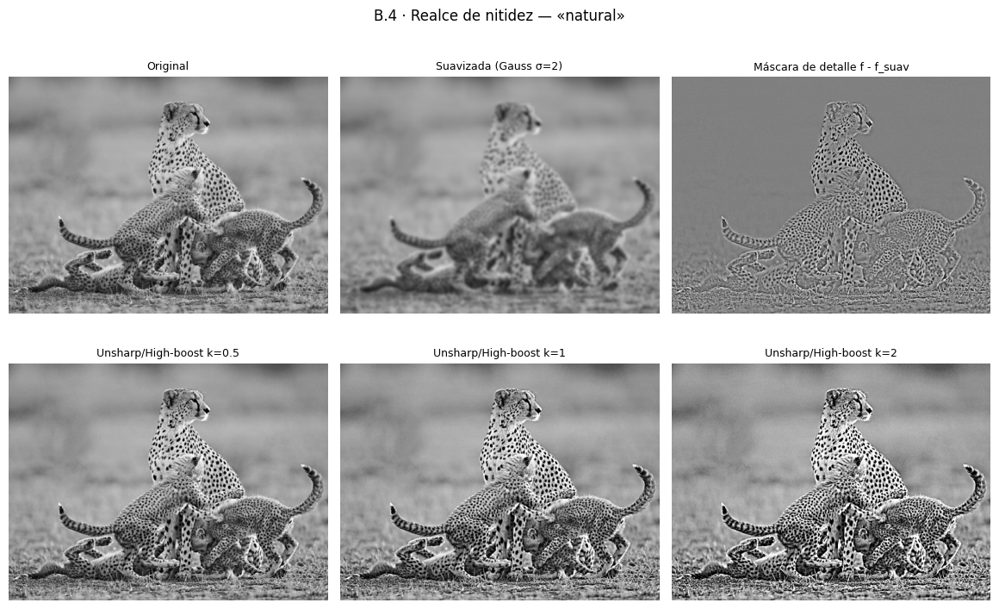

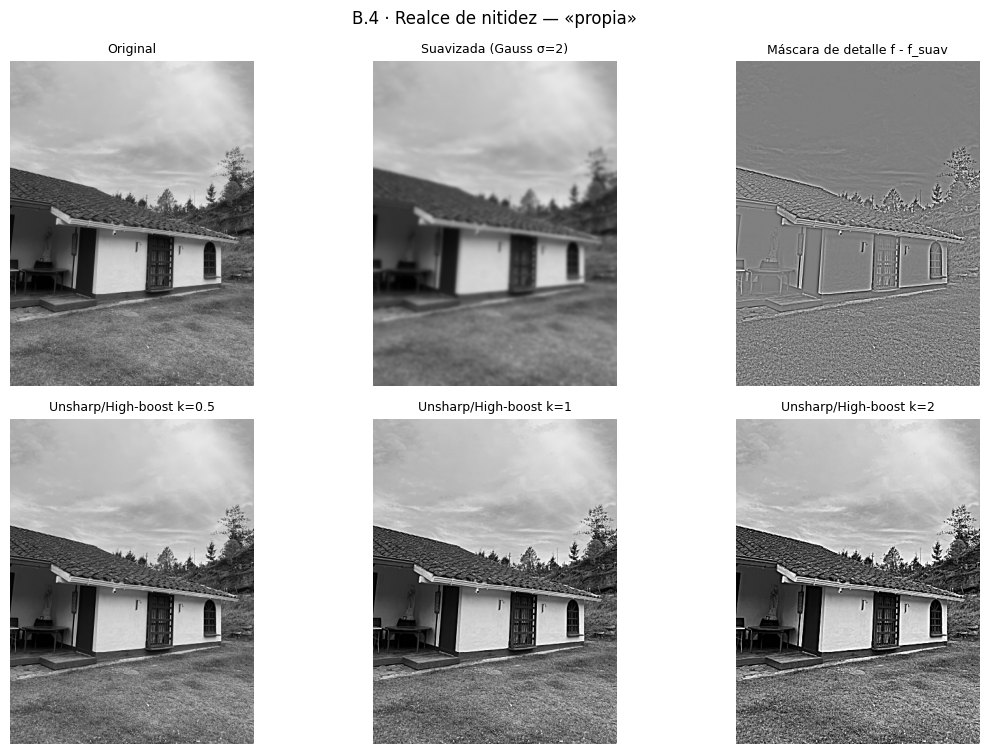

In [27]:
def unsharp(img, k, sigma=2.0, clip=True):
    f_ = img.astype(np.float64); b = gauss_f(f_, sigma)
    g = f_ + k*(f_ - b)
    return (a_uint8(g) if clip else g), b

# Verificación frente a cv2.addWeighted
img = IMAGENES['natural']; b8 = cv2.GaussianBlur(img, (ksize_sigma(2.0),)*2, 2.0)
aw = cv2.addWeighted(img, 1 + 1.0, b8, -1.0, 0)
print('Máx |unsharp propio - cv2.addWeighted| (k=1) =', np.abs(unsharp(img, 1.0)[0].astype(int) - aw.astype(int)).max(), '(diferencia por redondeo en uint8)')

for nombre, img in IMAGENES.items():
    _, b = unsharp(img, 1)
    ims = [img, a_uint8(b), vis_signed(img.astype(float) - b)] + [unsharp(img, k)[0] for k in (0.5, 1, 2)]
    tits = ['Original', 'Suavizada (Gauss σ=2)', 'Máscara de detalle f - f_suav'] + [f'Unsharp/High-boost k={k}' for k in (0.5, 1, 2)]
    mostrar(ims, tits, ncols=3, lado=3.9, suptitle=f'B.4 · Realce de nitidez — «{nombre}»')

k=0.5: sobreimpulso (halo claro) = +  7.0 niveles sobre 180 | subimpulso (halo oscuro) = -  7.0 niveles bajo 60
k=1: sobreimpulso (halo claro) = + 15.9 niveles sobre 180 | subimpulso (halo oscuro) = - 15.9 niveles bajo 60
k=2: sobreimpulso (halo claro) = + 38.7 niveles sobre 180 | subimpulso (halo oscuro) = - 38.7 niveles bajo 60


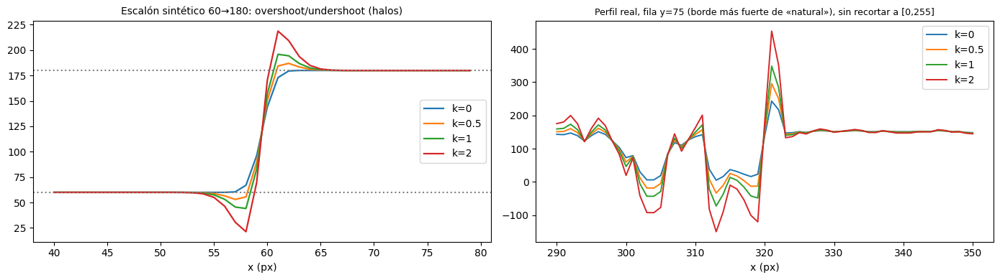

In [28]:
# ---- Análisis de HALOS: perfil de intensidad a través de un borde ----
# (1) Escalón sintético 60 -> 180, ligeramente suavizado, SIN recortar a [0,255] para ver el sobreimpulso real
st = np.full((40, 120), 60.0); st[:, 60:] = 180.0; st = cv2.GaussianBlur(st, (7, 7), 1.0)
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for k in (0, 0.5, 1, 2):
    g, _ = unsharp(st, k, sigma=2.0, clip=False); axs[0].plot(np.arange(40, 80), g[20, 40:80], label=f'k={k}', lw=1.6)
    if k: print(f'k={k}: sobreimpulso (halo claro) = +{g[20].max()-180:5.1f} niveles sobre 180 | subimpulso (halo oscuro) = -{60-g[20].min():5.1f} niveles bajo 60')
axs[0].axhline(180, c='gray', ls=':'); axs[0].axhline(60, c='gray', ls=':')
axs[0].set_title('Escalón sintético 60→180: overshoot/undershoot (halos)'); axs[0].set_xlabel('x (px)'); axs[0].legend()

# (2) Perfil sobre el borde más fuerte de una imagen real
img = IMAGENES['natural']; f_ = img.astype(np.float64)
mag = np.hypot(cv2.Sobel(gauss_f(f_, 1), cv2.CV_64F, 1, 0), cv2.Sobel(gauss_f(f_, 1), cv2.CV_64F, 0, 1))
mag[:, :35] = 0; mag[:, -35:] = 0
y0, x0 = np.unravel_index(np.argmax(mag), mag.shape)
for k in (0, 0.5, 1, 2):
    g, _ = unsharp(img, k, clip=False); axs[1].plot(np.arange(x0-30, x0+31), g[y0, x0-30:x0+31], label=f'k={k}', lw=1.4)
axs[1].set_title(f'Perfil real, fila y={y0} (borde más fuerte de «natural»), sin recortar a [0,255]', fontsize=9); axs[1].set_xlabel('x (px)'); axs[1].legend()
plt.tight_layout(); plt.show()

**Observaciones.**
* Con $k=0.5$ el realce es sutil y natural; con $k=1$ los detalles y bordes se ven claramente más nítidos; con $k=2$ (high-boost) el realce es agresivo: aparece un **aspecto "duro"**, se **amplifica el ruido** (la máscara $f-f_{suav}$ contiene el ruido de alta frecuencia además de los bordes) y aparecen **halos**.
* **¿Por qué los halos?** Junto a un borde, $f-f_{suav}$ es positivo en el lado claro y negativo en el lado oscuro (la versión suavizada "se sale" hacia el otro lado). Al sumar $k$ veces esa diferencia, el lado claro queda **más claro que el valor original** (*overshoot*) y el lado oscuro **más oscuro** (*undershoot*): se genera una franja clara y otra oscura a cada lado del borde, de ancho comparable a σ y amplitud proporcional a $k$ y al contraste del borde (las impresiones numéricas lo cuantifican). Esto *aumenta* el contraste local aparente (por eso "da nitidez") pero crea un contorno artificial; además, si los valores se salen de [0,255] se **recortan** (clipping), lo que empeora el efecto.
* Para controlar los halos: usar σ pequeño (halo más angosto), $k$ moderado o **umbralizar** la máscara para no realzar el ruido de zonas planas.

---
## Preguntas conceptuales del Módulo B

### Pregunta 1.4 – Ruido y derivadas
Se mide cuánto **amplifica** cada operador el ruido: se aplica a ruido Gaussiano blanco puro de σ = 10 y se compara la desviación de la salida con la de la entrada. Para un kernel $h$ y ruido blanco independiente, teóricamente $\sigma_{salida}=\sigma\,\|h\|_2=\sigma\sqrt{\sum h^2}$.

,||h||₂ (teórico),Amplificación medida σ_sal/σ_ent,σ de salida (σ_ent=10)
Prewitt Gx,2.449,2.450,24.498
Sobel Gx (3x3),3.464,3.462,34.624
Scharr Gx,15.362,15.349,153.494
Laplaciano 4 vecinos,4.472,4.471,44.707
Laplaciano 8 vecinos,8.485,8.476,84.756
LoG σ=1 (4v),0.335,0.334,3.336
LoG σ=2 (4v),0.048,0.048,0.477
LoG σ=3 (4v),0.015,0.015,0.146


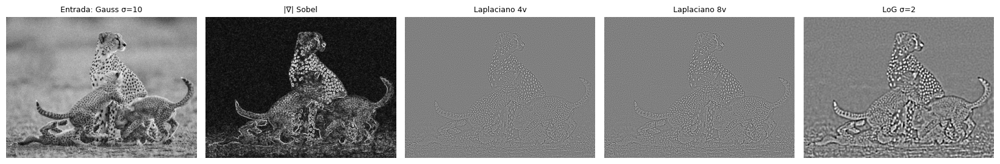

In [29]:
SIG_R = 10.0
ruido_puro = np.random.default_rng(1).normal(0, SIG_R, (512, 512))
impulso = np.zeros((101, 101)); impulso[50, 50] = 1.0

OPS_R = {
    'Prewitt Gx'            : lambda f: cv2.filter2D(f, cv2.CV_64F, K_PREW_X),
    'Sobel Gx (3x3)'        : lambda f: cv2.Sobel(f, cv2.CV_64F, 1, 0, ksize=3),
    'Scharr Gx'             : lambda f: cv2.Scharr(f, cv2.CV_64F, 1, 0),
    'Laplaciano 4 vecinos'  : lambda f: lap(f, K_LAP4),
    'Laplaciano 8 vecinos'  : lambda f: lap(f, K_LAP8),
    'LoG σ=1 (4v)'          : lambda f: log_(f, 1),
    'LoG σ=2 (4v)'          : lambda f: log_(f, 2),
    'LoG σ=3 (4v)'          : lambda f: log_(f, 3),
}
filas = {}
for t, op in OPS_R.items():
    norma = np.sqrt((op(impulso)**2).sum())                    # ||h||2 obtenido de la respuesta al impulso
    medido = op(ruido_puro).std()/SIG_R
    filas[t] = {'||h||₂ (teórico)': norma, 'Amplificación medida σ_sal/σ_ent': medido, 'σ de salida (σ_ent=10)': medido*SIG_R}
display(pd.DataFrame(filas).T.style.format('{:.3f}').set_caption('Amplificación del ruido blanco (valor <1 = atenúa; >1 = amplifica). Compara dentro de la misma familia: Scharr usa coeficientes de mayor escala (3,10,3) que Sobel (1,2,1).'))

# Visualización: misma imagen ruidosa derivada con distintos operadores
img = IMAGENES['natural']; rim = RUIDOSAS['natural']['Gauss σ=10']
mostrar([rim, vis_abs(np.hypot(*gradiente(rim, 'Sobel'))), vis_signed(lap(rim, K_LAP4)), vis_signed(lap(rim, K_LAP8)), vis_signed(log_(rim, 2))],
        ['Entrada: Gauss σ=10', '|∇| Sobel', 'Laplaciano 4v', 'Laplaciano 8v', 'LoG σ=2'], ncols=5, lado=3.3)

**Respuesta 1.4.**

**¿Por qué las derivadas amplifican el ruido?** En el dominio de la frecuencia, derivar equivale a multiplicar el espectro por $j\omega$ (primera derivada) o por $-\omega^2$ (segunda derivada): la ganancia **crece con la frecuencia**. El ruido es *de alta frecuencia* (ruido blanco: potencia plana en todo el espectro), mientras que la señal de la imagen concentra su energía en bajas frecuencias. Un derivador deja casi intacta la señal útil de baja frecuencia pero **multiplica el ruido de alta frecuencia**, empeorando la relación señal-ruido. En el dominio espacial el efecto es evidente: una derivada discreta *resta píxeles vecinos* cuyo ruido es independiente, así que la varianza del ruido se **suma** ($\operatorname{Var}(a-b)=2\sigma^2$), mientras que la diferencia debida a un borde real sólo ocurre en unos pocos píxeles.

**¿Por qué el Laplaciano es aún más sensible que Sobel?**
* Es una derivada de **segundo orden**: su ganancia crece como $\omega^2$ en vez de $\omega$.
* Sobel (y Prewitt) **incluye suavizado** en la dirección perpendicular (los pesos [1 2 1]) y usa una diferencia centrada de separación 2, que promedia ruido; el Laplaciano no suaviza nada. Además, tiene coeficientes con mayor norma: la tabla muestra que $\|h\|_2\approx3.46$ para Sobel, $\approx4.47$ para el Laplaciano de 4 vecinos y $\approx8.49$ para el de 8 vecinos (el de 8 vecinos es el más ruidoso, pues combina más píxeles con coeficientes grandes). El ruido de salida medido coincide con la teoría.
* Una segunda derivada detecta un borde como un *par* positivo-negativo y cualquier fluctuación aleatoria también produce cruces por cero espurios.

**¿Cómo lo resuelve el LoG?** Se **suaviza antes de derivar** con un Gaussiano: $\nabla^2(G_\sigma*f)=(\nabla^2G_\sigma)*f$. El Gaussiano atenúa las altas frecuencias (donde está el ruido) de modo que la respuesta total, $-\omega^2e^{-\sigma^2\omega^2/2}$, es un **filtro pasa-banda**: ya no crece indefinidamente. La tabla lo confirma: la amplificación del ruido **cae drásticamente** al pasar del Laplaciano directo al LoG, y baja más cuanto mayor es σ. El parámetro σ regula el compromiso: mayor σ ⇒ menos ruido pero menor resolución y bordes cercanos que se funden.

### Pregunta 1.5 – Histéresis en Canny
**Respuesta 1.5.**

**¿Por qué dos umbrales?** Con un **único umbral** hay un dilema sin buena solución (visible en las variantes de la celda anterior):
* Si es **alto**: sólo quedan bordes muy contrastados; en cuanto la magnitud del gradiente *se debilita* a lo largo de un contorno (por sombras, desenfoque, un tramo menos contrastado) el contorno **se rompe** en fragmentos y se pierden bordes reales débiles.
* Si es **bajo**: se conservan los bordes débiles, pero también todo el ruido y la textura, y aparecen muchos bordes espurios.

Con **dos umbrales** se separan las funciones: $T_{alto}$ garantiza **certeza** (un píxel con gradiente mayor que $T_{alto}$ es casi seguramente un borde real: "semilla") y $T_{bajo}$ define **hasta dónde se puede extender** un contorno a partir de la semilla. Un píxel débil sólo se acepta si está **conectado** a un píxel fuerte; los débiles aislados (típicamente ruido) se descartan. Relación recomendada: $T_{alto}:T_{bajo}\approx 2{:}1$ a $3{:}1$.

**Función de cada etapa en la continuidad de los contornos:**
* **Supresión de no-máximos:** la magnitud del gradiente forma una cresta *ancha* (varios píxeles) alrededor del borde. NMS conserva sólo el máximo local **a lo largo de la dirección del gradiente** (perpendicular al borde) y así produce curvas de **1 píxel de grosor** y bien localizadas. Esto es lo que permite que la histéresis siga un "hilo" delgado y que el mapa final sea un contorno limpio en vez de una banda.
* **Seguimiento por histéresis:** recorre la conectividad (8 vecinos) desde los píxeles fuertes a través de los débiles, **cerrando huecos** en los contornos y rechazando fragmentos aislados. Gracias a ello, los bordes resultan **continuos y conexos**, que es lo que necesitan los descriptores de forma de la Parte 2.

---
# Filtros extra
Se implementan los dos filtros marcados *(extra)* en el catálogo: el **filtro homomórfico** y las **máscaras de energía de Laws**.

## Filtro homomórfico
Una imagen se modela como **iluminación × reflectancia**: $f(x,y)=i(x,y)\cdot r(x,y)$. La iluminación varía lentamente (**bajas frecuencias**) y la reflectancia (detalle de los objetos) tiene **altas frecuencias**. Como el producto no se puede separar con un filtro lineal, se pasa a logaritmos, donde se vuelve una suma:

$$\ln f=\ln i+\ln r\;\xrightarrow{\ \text{FFT}\ }\;Z(u,v)\;\xrightarrow{\ \times H(u,v)\ }\;\xrightarrow{\ \text{IFFT}\ }\;\xrightarrow{\ \exp\ }\;g$$

con un filtro paso alto de énfasis (tipo Gaussiano):

$$H(u,v)=(\gamma_H-\gamma_L)\Big[1-e^{-c\,D^2(u,v)/D_0^2}\Big]+\gamma_L$$

* $\gamma_L<1$ **atenúa** las bajas frecuencias (iluminación) y $\gamma_H>1$ **amplifica** las altas (detalle). $D_0$ es la frecuencia de corte y $c$ controla la pendiente.
* Para verlo con claridad, se simula una **iluminación desigual** (la imagen se oscurece progresivamente hacia la izquierda y hacia abajo) y se intenta corregirla.

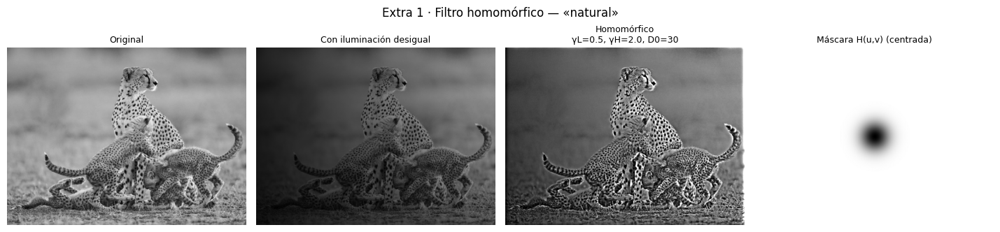

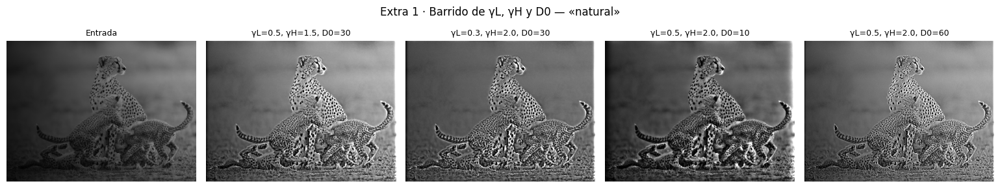

«natural» | razón de brillo derecha/izquierda — original: 0.97 | con iluminación desigual: 2.54 | homomórfico: 1.81  (más cerca de la original = mejor corrección)


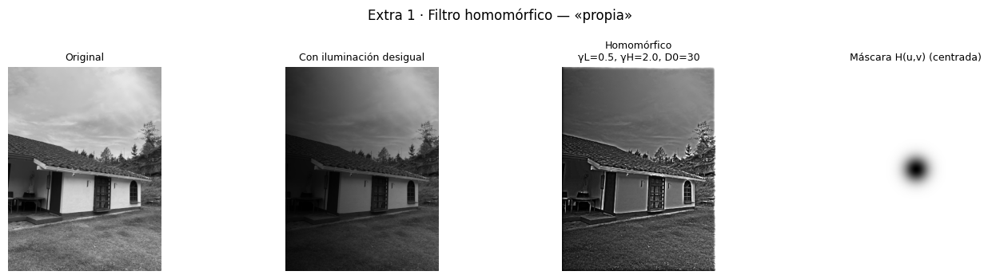

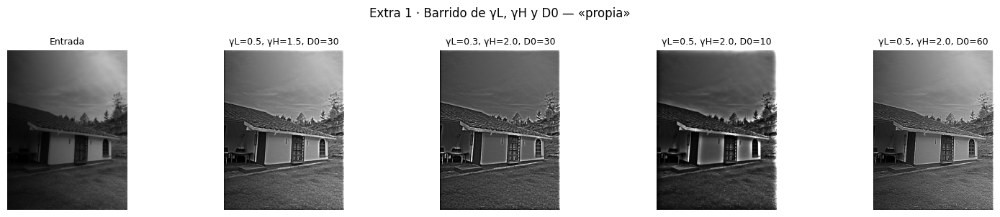

«propia» | razón de brillo derecha/izquierda — original: 1.26 | con iluminación desigual: 3.19 | homomórfico: 2.00  (más cerca de la original = mejor corrección)


In [30]:
def con_iluminacion_desigual(img):
    # Simula iluminación no uniforme: gradiente horizontal + viñeteo vertical (iluminación i(x,y) multiplicativa)
    H_, W_ = img.shape
    il = np.linspace(0.20, 1.0, W_)[None, :] * np.linspace(1.0, 0.55, H_)[:, None]
    return a_uint8(img.astype(np.float64) * il)

def homomorfico(img, gL=0.5, gH=2.0, D0=30, c=1.0):
    # log -> FFT -> H(u,v) -> IFFT -> exp. Devuelve (imagen en 0-255, máscara H)
    M, N = img.shape
    z = np.fft.fftshift(np.fft.fft2(np.log1p(img.astype(np.float64))))
    u = np.arange(M) - M/2; v = np.arange(N) - N/2
    V, U = np.meshgrid(v, u); D2 = U**2 + V**2                  # distancia al centro del espectro
    Hm = (gH - gL) * (1 - np.exp(-c * D2 / D0**2)) + gL
    g = np.expm1(np.real(np.fft.ifft2(np.fft.ifftshift(Hm * z))))
    lo, hi = np.percentile(g, 1), np.percentile(g, 99)           # estiramiento 1%-99% para visualizar
    return a_uint8(255 * np.clip((g - lo)/(hi - lo + 1e-12), 0, 1)), Hm

for nombre, img in IMAGENES.items():
    oscura = con_iluminacion_desigual(img)
    res, Hm = homomorfico(oscura, 0.5, 2.0, 30)
    mostrar([img, oscura, res, a_uint8(255*(Hm - Hm.min())/(Hm.max() - Hm.min()))],
            ['Original', 'Con iluminación desigual', 'Homomórfico\nγL=0.5, γH=2.0, D0=30', 'Máscara H(u,v) (centrada)'],
            ncols=4, lado=3.6, suptitle=f'Extra 1 · Filtro homomórfico — «{nombre}»')
    # Barrido de parámetros γL, γH, D0
    cfg = [(0.5, 1.5, 30), (0.3, 2.0, 30), (0.5, 2.0, 10), (0.5, 2.0, 60)]
    mostrar([oscura] + [homomorfico(oscura, *p)[0] for p in cfg],
            ['Entrada'] + [f'γL={a}, γH={b}, D0={d}' for a, b, d in cfg], ncols=5, lado=3.1,
            suptitle=f'Extra 1 · Barrido de γL, γH y D0 — «{nombre}»')
    # Métrica sencilla: razón entre el brillo medio del tercio derecho y el del izquierdo (la iluminación simulada crece hacia la derecha).
    # Una razón cercana a la de la imagen original indica que se corrigió la iluminación.
    def razon_lr(x): return x[:, -x.shape[1]//3:].mean() / (x[:, :x.shape[1]//3].mean() + 1e-9)
    print(f'«{nombre}» | razón de brillo derecha/izquierda — original: {razon_lr(img):.2f} | con iluminación desigual: {razon_lr(oscura):.2f} | '
          f'homomórfico: {razon_lr(res):.2f}  (más cerca de la original = mejor corrección)')

**Observaciones.**
* El filtro **recupera el detalle de las zonas oscuras** (a la izquierda y abajo) y **reduce la diferencia de iluminación** entre lados: la razón de brillo derecha/izquierda impresa se acerca a la de la imagen original. La corrección es **parcial** (con γ_L=0.5 las bajas frecuencias sólo se atenúan a la mitad en el dominio logarítmico) y el resultado tiene más contraste local porque $\gamma_H>1$. Cerca de los bordes de la imagen puede aparecer un leve *ringing*, porque la FFT supone una imagen periódica. Para una corrección más fuerte, baja γ_L (≈0.2) y/o usa un D₀ menor.
* **$\gamma_L$ más bajo** (0.3) corrige más la iluminación pero la imagen pierde "volumen" y se ve más plana; **$\gamma_H$ más alto** realza más el detalle (y el ruido).
* **$D_0$ pequeño** (10) sólo trata como iluminación las frecuencias más bajas: la corrección es parcial. **$D_0$ grande** (60) trata como iluminación una banda más ancha, y empieza a alterar el contraste de los objetos y a producir un aspecto "aplastado".
* Es útil como preprocesamiento antes de segmentar o extraer descriptores en la Parte 2 cuando las fotos tienen sombras o iluminación irregular. (Retoma además el dominio de Fourier del Módulo D, 2.5.)

## Máscaras de energía de Laws
Laws construye máscaras 5×5 como **productos externos** de cuatro vectores 1D de longitud 5:

| Vector | Valores | Mide |
|---|---|---|
| **L5** | `[ 1, 4, 6, 4, 1]` | Nivel (promedio, suavizado) |
| **E5** | `[-1,-2, 0, 2, 1]` | Bordes (*edges*) |
| **S5** | `[-1, 0, 2, 0,-1]` | Manchas (*spots*) |
| **R5** | `[ 1,-4, 6,-4, 1]` | Ondulaciones (*ripples*) |

Procedimiento: (1) **restar la media local** (15×15) para normalizar la iluminación; (2) convolucionar con cada máscara $a^T b$ (`cv2.filter2D`); (3) calcular la **energía** = promedio local de $|{\rm respuesta}|$ en una ventana de 15×15; (4) combinar pares simétricos (p. ej. L5E5 y E5L5) promediándolos. Se excluye L5L5 (sólo mide nivel de gris). Resultan **9 mapas de energía** de textura.

Ejemplo, máscara E5·S5ᵀ (bordes × manchas):
 [[ 1  0 -2  0  1]
 [ 2  0 -4  0  2]
 [ 0  0  0  0  0]
 [-2  0  4  0 -2]
 [-1  0  2  0 -1]]
Suma de coeficientes de L5E5 = 0.0 (≈0: no responde a zonas planas)


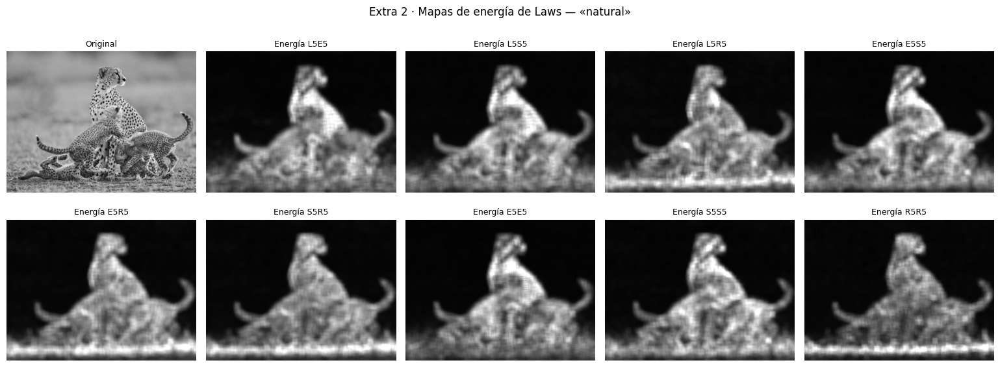

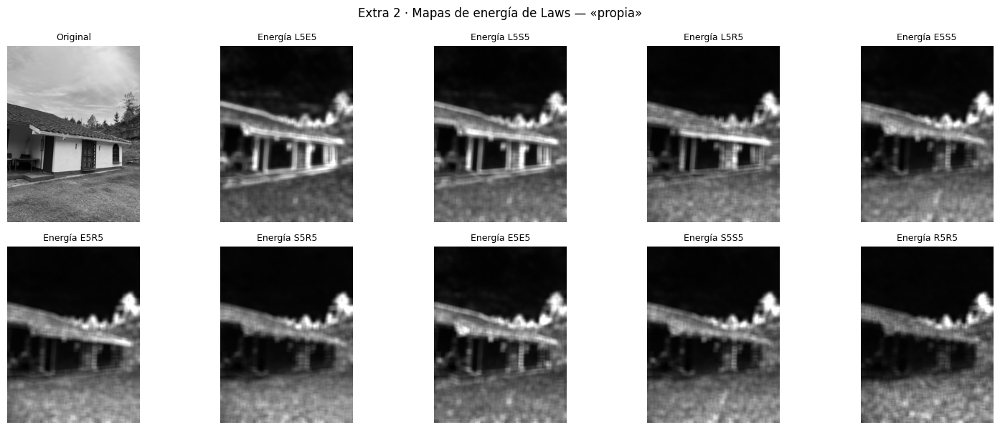

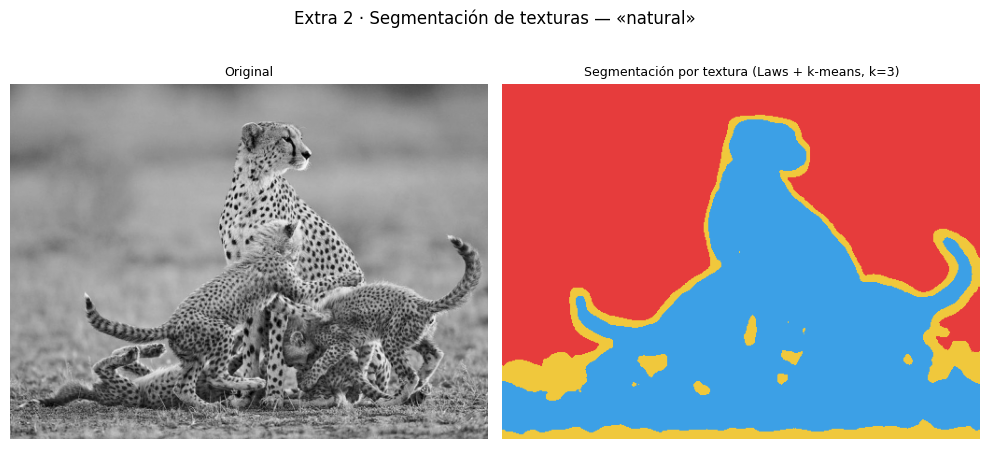

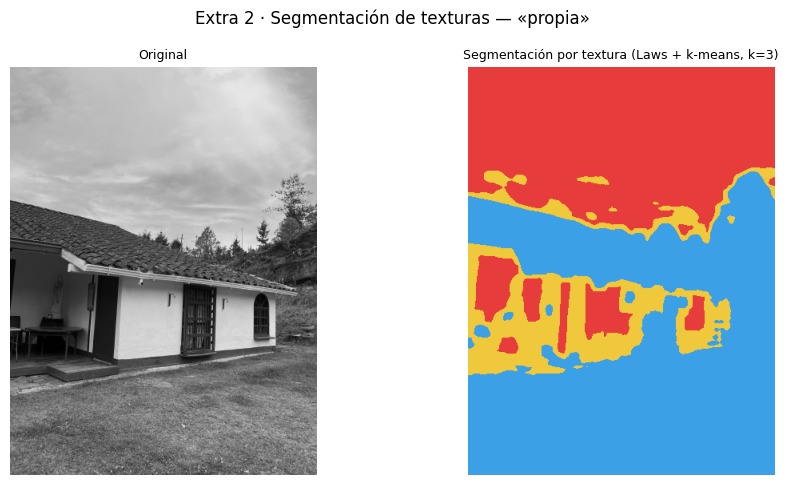

In [31]:
V1D = {'L5': np.array([1, 4, 6, 4, 1], np.float64), 'E5': np.array([-1, -2, 0, 2, 1], np.float64),
       'S5': np.array([-1, 0, 2, 0, -1], np.float64), 'R5': np.array([1, -4, 6, -4, 1], np.float64)}

def mascara_laws(a, b):
    return np.outer(V1D[a], V1D[b])                      # máscara 5x5 = a^T b

def laws_energia(img, a, b, ventana=15):
    f_ = img.astype(np.float64); f_ = f_ - cv2.blur(f_, (ventana, ventana))     # (1) quitar media local
    def energia(p, q):
        r = cv2.filter2D(f_, cv2.CV_64F, mascara_laws(p, q))                    # (2) convolución con la máscara
        return cv2.boxFilter(np.abs(r), -1, (ventana, ventana))                 # (3) energía local
    return energia(a, b) if a == b else (energia(a, b) + energia(b, a))/2       # (4) par simétrico

PARES_LAWS = [('L5','E5'), ('L5','S5'), ('L5','R5'), ('E5','S5'), ('E5','R5'), ('S5','R5'), ('E5','E5'), ('S5','S5'), ('R5','R5')]
print('Ejemplo, máscara E5·S5ᵀ (bordes × manchas):\n', mascara_laws('E5', 'S5').astype(int))
print('Suma de coeficientes de L5E5 =', mascara_laws('L5', 'E5').sum(), '(≈0: no responde a zonas planas)')

MAPAS_LAWS = {}
for nombre, img in IMAGENES.items():
    mapas = [laws_energia(img, a, b) for a, b in PARES_LAWS]; MAPAS_LAWS[nombre] = mapas
    mostrar([img] + [vis_abs(m) for m in mapas], ['Original'] + [f'Energía {a}{b}' for a, b in PARES_LAWS],
            ncols=5, lado=3.1, suptitle=f'Extra 2 · Mapas de energía de Laws — «{nombre}»')

# Aplicación: segmentación de texturas agrupando los 9 mapas de energía con k-means (k=3)
from sklearn.cluster import KMeans
PALETA = np.array([[230, 60, 60], [60, 160, 230], [240, 200, 60], [100, 200, 100]], np.uint8)
for nombre, img in IMAGENES.items():
    X_ = np.log1p(np.stack([m.ravel() for m in MAPAS_LAWS[nombre]], axis=1))
    X_ = (X_ - X_.mean(0)) / (X_.std(0) + 1e-9)
    etiquetas = KMeans(n_clusters=3, n_init=4, random_state=RNG_SEED).fit_predict(X_).reshape(img.shape)
    mostrar([img, PALETA[etiquetas]], ['Original', 'Segmentación por textura (Laws + k-means, k=3)'], ncols=2, lado=5,
            suptitle=f'Extra 2 · Segmentación de texturas — «{nombre}»')

**Observaciones.**
* Los mapas con **E5** (bordes), **S5** (manchas) y **R5** (ondulaciones) tienen **energía alta en regiones con textura** (pelaje manchado, follaje, tejas, pasto) y **baja en regiones suaves** (cielo, pared lisa, fondo desenfocado). Cada máscara responde a un tipo distinto de patrón: p. ej. E5E5 y E5S5 resaltan estructuras de borde y de manchas, mientras que R5R5 sólo responde a oscilaciones muy finas.
* Restar la media local antes de filtrar hace que la energía dependa de la **textura** y no del brillo.
* Agrupar los 9 mapas con k-means separa regiones según su textura *sin usar color ni forma*. Es un descriptor de textura listo para la **Parte 2** (junto con HOG, forma y color).

---
## Galería resumen


In [32]:
for nombre, img in IMAGENES.items():
    sp = RUIDOSAS[nombre]['S&P 5%']
    items = [
        ('Original', img), ('Ruido sal y pimienta 5%', sp),
        ('Media 5x5', cv2.blur(sp, (5, 5))), ('Mediana 5x5', cv2.medianBlur(sp, 5)),
        ('Gaussiano σ=2', cv2.GaussianBlur(img, (ksize_sigma(2),)*2, 2)), ('Bilateral (9,75,75)', cv2.bilateralFilter(img, 9, 75, 75)),
        ('Sobel |∇f|', vis_abs(np.hypot(*gradiente(img, 'Sobel')))), ('Scharr |∇f|', vis_abs(np.hypot(*gradiente(img, 'Scharr')))),
        ('Laplaciano 8v', vis_signed(lap(img, K_LAP8))), ('LoG σ=2', vis_signed(log_(img, 2))),
        ('DoG σ=2/3.2', vis_signed(dog(img, 2))), ('Canny σ=2, 50/150', cv2.Canny(cv2.GaussianBlur(img, (ksize_sigma(2),)*2, 2), 50, 150)),
        ('Unsharp k=1', unsharp(img, 1)[0]), ('High-boost k=2', unsharp(img, 2)[0]),
        ('NLM h=15', cv2.fastNlMeansDenoising(img, None, h=15)),
        ('Roberts |∇f|', vis_abs(np.hypot(*gradiente(img, 'Roberts')))), ('Prewitt |∇f|', vis_abs(np.hypot(*gradiente(img, 'Prewitt')))),
        ('Laplaciano 4v', vis_signed(lap(img, K_LAP4))), ('Entrada con iluminación desigual', con_iluminacion_desigual(img)),
        ('EXTRA Homomórfico\n(sobre la anterior)', homomorfico(con_iluminacion_desigual(img), 0.5, 2.0, 30)[0]),
        ('EXTRA Laws E5S5 (energía)', vis_abs(MAPAS_LAWS[nombre][3])), ('EXTRA Laws L5E5 (energía)', vis_abs(MAPAS_LAWS[nombre][0])),
        ('EXTRA Laws R5R5 (energía)', vis_abs(MAPAS_LAWS[nombre][8])),
    ]
    mostrar([i for _, i in items], [t for t, _ in items], ncols=5, lado=2.9, suptitle=f'Galería de filtros (Módulos A y B + extras) — «{nombre}»')

Output hidden; open in https://colab.research.google.com to view.

---
## Conclusiones del taller (Secciones 2.1–2.3)

| Tema | Idea clave |
|---|---|
| **Convolución** | Voltea el kernel; `cv2.filter2D` es *correlación*. El tipo de borde importa (el `CONSTANT` oscurece el marco). Mover los ciclos de píxeles a kernel + NumPy o usar `cv2` marca la diferencia en tiempo. |
| **Suavizado lineal** | Reduce ruido Gaussiano a costa de emborronar; los kernels deben sumar 1 para conservar el brillo. El Gaussiano es separable (2K en vez de K² operaciones). |
| **Filtros de orden** | La mediana es el filtro de elección para ruido impulsivo (punto de ruptura 50 %). Mínimo y máximo no son filtros de ruido. |
| **Bilateral / NLM** | No lineales; preservan bordes comparando intensidades (bilateral) o parches (NLM). El bilateral no sirve para sal y pimienta. |
| **Gradiente** | Derivar siempre en `CV_64F`. Prewitt < Sobel < Scharr en isotropía; Roberts es el más sensible al ruido. |
| **2ª derivada** | El Laplaciano amplifica el ruido; el LoG lo controla con σ; el DoG (razón 1.6) lo aproxima con menos costo. |
| **Canny** | Suavizado → gradiente → NMS → doble umbral + histéresis. σ y los umbrales son un compromiso ruido/detalle; la regla de la mediana adapta los umbrales a la exposición. |
| **Realce** | Unsharp/high-boost suman detalle de alta frecuencia; k grande produce halos y amplifica el ruido. |

**Conexión con la Parte 2:** los operadores de gradiente (B.1) son la base del **HOG**; Canny (B.3) y el preprocesamiento de ruido (A.3) serán útiles en la **segmentación** y extracción de descriptores de forma.

**Extras:** el filtro homomórfico corrige iluminación irregular (útil como preprocesamiento) y las máscaras de Laws dan descriptores de textura para la Parte 2.

**Pendiente (Secciones 2.4 y 2.5):** Módulo C (transformaciones de intensidad), Módulo D (dominio de la frecuencia: Fourier, Butterworth, notch, equivalencia espacio–frecuencia) y banco de filtros de Gabor.